# Inteligencia de Datos para la Retención del Talento en IBM


**Bootcamp 702 · Talento Tech · Nivel Explorador · Análisis de Datos**

| | |
|---|---|
| **Equipo** | Proyecto grupal de 4 integrantes: Líder, Datos, Análisis (Karen Noreña) e Informe |
| **Dataset** | IBM HR Analytics Employee Attrition & Performance |
| **Fuente** | Kaggle / IBM Watson Analytics |
| **Fecha** | Junio 6 2026 |
| **Herramientas** | Python · Pandas · NumPy · Matplotlib · Seaborn |

---

## Sección 1 — Introducción y Pregunta de Investigación

### 1.1 Contexto del problema

La rotación de personal es uno de los principales desafíos en la gestión del talento humano dentro del sector tecnológico. Cuando un empleado abandona voluntariamente una organización, la empresa incurre en costos directos (reclutamiento, capacitación) e indirectos (pérdida de conocimiento, impacto en el clima laboral).

Según estudios del sector, reemplazar a un empleado puede costar entre el **50% y el 200% de su salario anual**, dependiendo del nivel del cargo. Entender qué factores se asocian con la decisión de renuncia permite a las organizaciones diseñar estrategias de retención más efectivas y focalizadas.

### 1.2 Pregunta de investigación

> **¿Qué factores demográficos (género, estado civil), laborales (departamento, horas extra, nivel salarial) y de satisfacción (satisfacción laboral, desempeño) se asocian con mayor probabilidad de rotación voluntaria en los empleados de IBM, y cuáles presentan la relación más fuerte según departamento?**

### 1.3 Objetivo del análisis

Realizar un análisis exploratorio descriptivo del dataset IBM HR Analytics para identificar los factores con mayor asociación con la rotación voluntaria de empleados, comparando perfiles de empleados que permanecen en la empresa frente a quienes la abandonan, segmentado por departamento.

### 1.4 Justificación

Este análisis es relevante para áreas de Recursos Humanos, Gerencia y equipos de People Analytics, ya que los hallazgos pueden orientar decisiones sobre políticas salariales, gestión de carga laboral, programas de bienestar y estrategias de retención diferenciadas por perfil de empleado.

---
## Sección 1 — Configuración del Entorno

En esta sección importamos todas las librerías necesarias para el análisis y configuramos los parámetros globales de visualización. Esto garantiza que el notebook sea reproducible desde el inicio.

In [ ]:
# Importación de Librerias

# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Configuración de advertencias
import warnings
warnings.filterwarnings('ignore')

# CONFIGURACIÓN GLOBAL DE VISUALIZACIÓN

# Estilo general de seaborn
sns.set_theme(style='darkgrid', palette='muted', font_scale=1.1)

# Paleta de colores principal del proyecto
# Azul = empleados que permanecen (No rotación)
# Rojo/Naranja = empleados que rotan (Sí rotación)
PALETA_ROTACION = {'No': '#730d0d', 'Yes': '#cf1717'}
COLOR_PRINCIPAL = '#730d0d'
COLOR_ACENTO = '#cf1717'

# Tamaño de figura por defecto
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print('Librerías importadas y configuración lista.')

Librerías importadas y configuración lista.


---
## Sección 2 — Fuente de Datos

### 2.1 Ficha de la fuente

| Campo | Detalle |
|---|---|
| **Nombre del dataset** | IBM HR Analytics Employee Attrition & Performance |
| **Entidad/Origen** | IBM Watson Analytics / Kaggle |
| **Enlace** | https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset |
| **Tipo de datos** | Datos tabulares (CSV) |
| **Número de registros** | 1,470 empleados |
| **Número de variables** | 35 columnas |
| **Fecha de descarga** | Junio 2025 |
| **Período que cubre** | Snapshot histórico (sin fecha específica) |
| **Licencia** | Uso público - educativo |

### 2.2 Descripción de variables clave

| Variable | Tipo | Descripción |
|---|---|---|
| `Rotacion` | Categórica (Yes/No) | **Variable objetivo**: si el empleado abandonó la empresa |
| `Genero` | Categórica | Género del empleado |
| `EstadoCivil` | Categórica | Estado civil (Single, Married, Divorced) |
| `Departamento` | Categórica | Departamento (HR, R&D, Sales) |
| `HorasExtra` | Categórica (Yes/No) | Si el empleado hace horas extra |
| `IngresoMensual` | Numérica | Ingreso mensual en dólares |
| `SatisfaccionLaboral` | Ordinal (1-4) | Nivel de satisfacción laboral |
| `EvaluacionRendimiento` | Ordinal (1-4) | Calificación de desempeño |
| `AniosEnEmpresa` | Numérica | Años en la empresa |
| `Edad` | Numérica | Edad del empleado |
| `EquilibrioTrabajoVida` | Ordinal (1-4) | Balance vida-trabajo |
| `SatisfaccionAmbiente` | Ordinal (1-4) | Satisfacción con el ambiente laboral |

### 2.3 Limitación importante

> **Nota metodológica:** El dataset IBM HR no distingue entre rotación **voluntaria** (renuncia) e **involuntaria** (despido). Para efectos de este análisis, asumimos que la variable `Rotacion = Yes` refleja principalmente rotación voluntaria, dado que el contexto del dataset así lo documenta en la literatura. Esta limitación se reconoce y se menciona en las conclusiones.

### 2.4 Carga del dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Carga del Dataset

df = pd.read_csv('/content/drive/MyDrive/Bootcamp_ADA_702/Proyecto_final/Dataset/data_set_IBM/recursos_humanos_ibm.csv', sep=',', index_col=0)
df

print(f'Dataset cargado correctamente.')
print(f'Filas    : {df.shape[0]:,}')
print(f'Columnas : {df.shape[1]}')

Dataset cargado correctamente.
Filas    : 1,470
Columnas : 35


## Sección 3 — Exploración Inicial del Dataset

Antes de limpiar o analizar los datos, realizamos una exploración inicial para entender su estructura, tipos de variables y calidad general. Esta fase responde tres preguntas básicas:
- ¿Qué forma tienen los datos?
- ¿Qué tipo es cada variable?
- ¿Existen valores faltantes o duplicados?

In [ ]:
# 3.1 Primeras filas del Dataset
print('Primeras 5 filas del dataset:')
df.head()

Primeras 5 filas del dataset:


,Edad,Rotacion,ViajeNegocios,TarifaDiaria,Departamento,DistanciaCasa,Educacion,CampoEducacion,CantidadEmpleados,NumeroEmpleado,...,SatisfaccionRelaciones,HorasEstandar,NivelOpcionesAcciones,AniosTotalesTrabajo,VecesEntrenamientoUltimoAnio,EquilibrioTrabajoVida,AniosEnEmpresa,AniosEnRolActual,AniosDesdeUltimaPromocion,AniosConGerenteActual
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
# 3.2 Información General De Columnas y Tipos de Datos

print('Información del dataset:')
df.info()

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Edad                          1470 non-null   int64 
 1   Rotacion                      1470 non-null   object
 2   ViajeNegocios                 1470 non-null   object
 3   TarifaDiaria                  1470 non-null   int64 
 4   Departamento                  1470 non-null   object
 5   DistanciaCasa                 1470 non-null   int64 
 6   Educacion                     1470 non-null   int64 
 7   CampoEducacion                1470 non-null   object
 8   CantidadEmpleados             1470 non-null   int64 
 9   NumeroEmpleado                1470 non-null   int64 
 10  SatisfaccionAmbiente          1470 non-null   int64 
 11  Genero                        1470 non-null   object
 12  TarifaPorHora                 1470 non-null   int64 
 13

In [ ]:
# 3.3 Estadísticas Descriptivas y variables númericas

print('Estadísticos descriptivos de variables numéricas:')
df.describe().round(2)

Estadísticos descriptivos de variables numéricas:


,Edad,TarifaDiaria,DistanciaCasa,Educacion,CantidadEmpleados,NumeroEmpleado,SatisfaccionAmbiente,TarifaPorHora,InvolucramientoLaboral,NivelLaboral,...,SatisfaccionRelaciones,HorasEstandar,NivelOpcionesAcciones,AniosTotalesTrabajo,VecesEntrenamientoUltimoAnio,EquilibrioTrabajoVida,AniosEnEmpresa,AniosEnRolActual,AniosDesdeUltimaPromocion,AniosConGerenteActual
count,1470.00,1470.00,1470.00,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,...,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00
mean,36.92,802.49,9.19,2.91,1.0,1024.87,2.72,65.89,2.73,2.06,...,2.71,80.0,0.79,11.28,2.80,2.76,7.01,4.23,2.19,4.12
std,9.14,403.51,8.11,1.02,0.0,602.02,1.09,20.33,0.71,1.11,...,1.08,0.0,0.85,7.78,1.29,0.71,6.13,3.62,3.22,3.57
min,18.00,102.00,1.00,1.00,1.0,1.00,1.00,30.00,1.00,1.00,...,1.00,80.0,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,30.00,465.00,2.00,2.00,1.0,491.25,2.00,48.00,2.00,1.00,...,2.00,80.0,0.00,6.00,2.00,2.00,3.00,2.00,0.00,2.00
50%,36.00,802.00,7.00,3.00,1.0,1020.50,3.00,66.00,3.00,2.00,...,3.00,80.0,1.00,10.00,3.00,3.00,5.00,3.00,1.00,3.00
75%,43.00,1157.00,14.00,4.00,1.0,1555.75,4.00,83.75,3.00,3.00,...,4.00,80.0,1.00,15.00,3.00,3.00,9.00,7.00,3.00,7.00
max,60.00,1499.00,29.00,5.00,1.0,2068.00,4.00,100.00,4.00,5.00,...,4.00,80.0,3.00,40.00,6.00,4.00,40.00,18.00,15.00,17.00


In [ ]:
# 3.4 Resumen de Variables Categoricas

print('Resumen de variables categóricas:\n')
cols_cat = df.select_dtypes(include='object').columns

for col in cols_cat:
    print(f'  [{col}] — {df[col].nunique()} valores únicos: {df[col].unique().tolist()}')

Resumen de variables categóricas:

  [Rotacion] — 2 valores únicos: ['Yes', 'No']
  [ViajeNegocios] — 3 valores únicos: ['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
  [Departamento] — 3 valores únicos: ['Sales', 'Research & Development', 'Human Resources']
  [CampoEducacion] — 6 valores únicos: ['Life Sciences', 'Other', 'Medical', 'Marketing', 'Technical Degree', 'Human Resources']
  [Genero] — 2 valores únicos: ['Female', 'Male']
  [RolLaboral] — 9 valores únicos: ['Sales Executive', 'Research Scientist', 'Laboratory Technician', 'Manufacturing Director', 'Healthcare Representative', 'Manager', 'Sales Representative', 'Research Director', 'Human Resources']
  [EstadoCivil] — 3 valores únicos: ['Single', 'Married', 'Divorced']
  [MayorDe18] — 1 valores únicos: ['Y']
  [HorasExtra] — 2 valores únicos: ['Yes', 'No']


In [ ]:
# 3.5 Valores Faltantes

nulos = df.isnull().sum()
nulos_pct = (nulos / len(df) * 100).round(2)

resumen_nulos = pd.DataFrame({
    'Valores faltantes': nulos,
    'Porcentaje (%)': nulos_pct
}).sort_values('Valores faltantes', ascending=False)

# Solo mostramos columnas con al menos 1 nulo
nulos_encontrados = resumen_nulos[resumen_nulos['Valores faltantes'] > 0]

if len(nulos_encontrados) == 0:
    print('No se encontraron valores faltantes en ninguna columna.')
else:
    print(f'Se encontraron valores faltantes en {len(nulos_encontrados)} columna(s):')
    display(nulos_encontrados)

No se encontraron valores faltantes en ninguna columna.


In [ ]:
# 3.6 Filas Duplicadas

duplicados = df.duplicated().sum()

if duplicados == 0:
    print('No se encontraron filas duplicadas.')
else:
    print(f'Se encontraron {duplicados} filas duplicadas.')
    print('Se eliminarán en la fase de limpieza.')

No se encontraron filas duplicadas.


Distribución de la variable objetivo (Rotacion):

          Cantidad  Porcentaje (%)
Rotacion                          
No            1233            83.9
Yes            237            16.1



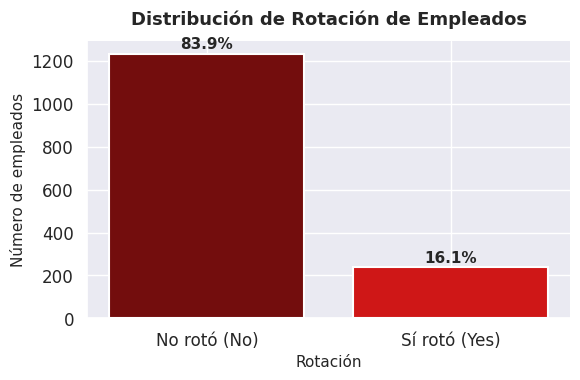


Gráfico guardado como fig_00_distribucion_rotacion.png


In [ ]:
# 3.7 Distribución de la variable Objetivo: Rotacion

conteo = df['Rotacion'].value_counts()
pct = df['Rotacion'].value_counts(normalize=True).mul(100).round(1)

print('Distribución de la variable objetivo (Rotacion):\n')
resumen_target = pd.DataFrame({'Cantidad': conteo, 'Porcentaje (%)': pct})
print(resumen_target)

# Gráfico
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(conteo.index, conteo.values, color=[PALETA_ROTACION['No'], PALETA_ROTACION['Yes']], edgecolor='white', linewidth=1.5)

# Etiquetas sobre las barras
for bar, p in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, f'{p}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_title('Distribución de Rotación de Empleados', fontweight='bold', pad=12)
ax.set_xlabel('Rotación')
ax.set_ylabel('Número de empleados')
ax.set_xticks([0, 1])
ax.set_xticklabels(['No rotó (No)', 'Sí rotó (Yes)'])
sns.despine() #Elimina el borde superior
plt.tight_layout() #Distribuye la info para que quede dentro del cuarto
plt.savefig('fig_00_distribucion_rotacion.png', dpi=150, bbox_inches='tight') #Guarda la imagen
print()
plt.show() # Muestra la imagen
print()
print('Gráfico guardado como fig_00_distribucion_rotacion.png')

### Observaciones de la exploración inicial

- El dataset contiene **1,470 registros y 35 columnas**.
- La variable objetivo `Rotacion` está **desbalanceada**: aproximadamente el 16% de los empleados presenta rotación (`Yes`) frente al 84% que permanece (`No`). Esto es importante tenerlo en cuenta en el análisis e interpretación.
- No hay nulos ni duplicados en el dataset
- Se identificaron variables numéricas, categóricas y ordinales que requieren tratamiento diferenciado.

## Sección 4 — Limpieza de Datos

En esta sección aplicamos las transformaciones necesarias para dejar los datos confiables y listos para el análisis.

In [ ]:
# 4.0 Copia de Seguridad del dataSet original

# Trabajamos siempre sobre una copia para no alterar el original.
df_clean = df.copy()
print(f'Se crea una copia de seguridad: df_clean ({df_clean.shape[0]} filas × {df_clean.shape[1]} columnas)')

Se crea una copia de seguridad: df_clean (1470 filas × 35 columnas)


### 4.1 ELIMINACIÓN DE COLUMNAS CONSTANTES (SIN VARIABILIDAD)

Estas columnas contienen el mismo valor para todos los empleados, por lo tanto no aportan información útil al análisis ni al modelo predictivo.

**Columnas identificadas previamente:**
*   `CantidadEmpleados` → siempre = 1
*   `MayorDe18`         → siempre = 'Y'
*   `HorasEstandar`     → siempre = 80

También se eliminó `Unnamed: 0` (generalmente el índice) y `NumeroEmpleado` (es un ID, no aporta al análisis).

In [ ]:
cols_to_drop = [
    'Unnamed: 0',
    'CantidadEmpleados',
    'MayorDe18',
    'HorasEstandar',
    'NumeroEmpleado'
]

print('Identificando y eliminando columnas constantes e identificadores irrelevantes...')

cols_to_drop_actual = [col for col in cols_to_drop if col in df_clean.columns]

if cols_to_drop_actual:
    cols_antes = df_clean.shape[1]
    df_clean.drop(columns=cols_to_drop_actual, inplace=True)
    cols_despues = df_clean.shape[1]

    num_dropped = cols_antes - cols_despues

    print(f'Se eliminaron {num_dropped} columna(s):')
    for col in cols_to_drop_actual:
        print(f'• {col}')
else:
    print('No se encontraron las columnas especificadas para eliminar en el DataFrame o ya fueron eliminadas.')

print('\nDATASET ACTUALIZADO')
print(f'Filas: {df_clean.shape[0]}')
print(f'Columnas: {df_clean.shape[1]}')

Identificando y eliminando columnas constantes e identificadores irrelevantes...
Se eliminaron 4 columna(s):
• CantidadEmpleados
• MayorDe18
• HorasEstandar
• NumeroEmpleado

DATASET ACTUALIZADO
Filas: 1470
Columnas: 31


### Eliminación de columnas adicionales

Como seguimiento a la discusión previa sobre el número de columnas en `df_clean`, y ya que las columnas iniciales no relevantes (`Unnamed: 0`, `CantidadEmpleados`, etc.) fueron eliminadas en pasos anteriores, si se desea reducir aún más el número de columnas para centrarse en las características principales, se puede eliminar `JobSatisfaction_label`.

In [ ]:
cols_to_remove = ['JobSatisfaction_label']

# Verificar si las columnas existen antes de intentar eliminarlas
existing_cols_to_remove = [col for col in cols_to_remove if col in df_clean.columns]

if existing_cols_to_remove:
    df_clean.drop(columns=existing_cols_to_remove, inplace=True)
    print(f"Columnas eliminadas: {existing_cols_to_remove}")
else:
    print("Las columnas especificadas ya no existen en el DataFrame.")

print(f'Dimensiones actuales de df_clean: {df_clean.shape[0]} filas x {df_clean.shape[1]} columnas')

Las columnas especificadas ya no existen en el DataFrame.
Dimensiones actuales de df_clean: 1470 filas x 31 columnas


In [ ]:
# 4.2 ELIMINACIÓN DE FILAS DUPLICADAS

# Decisión: si existen filas completamente duplicadas,
# se eliminan ya que representarían el mismo empleado dos veces.

n_antes = len(df_clean)
df_clean.drop_duplicates(inplace=True)
n_despues = len(df_clean)

eliminados = n_antes - n_despues
if eliminados == 0:
    print('No se encontraron duplicados. Dataset sin cambios.')
else:
    print(f'Se eliminaron {eliminados} filas duplicadas.')
    print(f'Dataset ahora: {df_clean.shape[0]} filas × {df_clean.shape[1]} columnas')

No se encontraron duplicados. Dataset sin cambios.


In [ ]:
# 4.3 CODIFICACIÓN DE VARIABLE OBJETIVO: Rotacion → 0/1

# Decisión: creamos una columna numérica 'rotacion_num' para
# facilitar correlaciones y análisis estadístico.
#   Yes → 1 (rotan)
#   No  → 0 (permanecen)
# Se conserva la columna original 'Rotacion' para gráficos.

df_clean['rotacion_num'] = df_clean['Rotacion'].map({'Yes': 1, 'No': 0})

print('Columna rotacion_num creada:')
print(df_clean[['Rotacion', 'rotacion_num']].value_counts().reset_index())

Columna rotacion_num creada:
  Rotacion  rotacion_num  count
0       No             0   1233
1      Yes             1    237


In [ ]:
# 4.4 CODIFICACIÓN DE HorasExtra → 0/1

# Decisión: convertimos HorasExtra a numérico para incluirla
# en análisis de correlación.
#   Yes → 1 (hace horas extra)
#   No  → 0 (no hace horas extra)

df_clean['HorasExtra_num'] = df_clean['HorasExtra'].map({'Yes': 1, 'No': 0})

print('Columna HorasExtra_num creada:')
print(df_clean[['HorasExtra', 'HorasExtra_num']].value_counts().reset_index())

Columna HorasExtra_num creada:
  HorasExtra  HorasExtra_num  count
0         No               0   1054
1        Yes               1    416


In [ ]:
# 4.5 VERIFICACIÓN DE TIPOS DE DATOS FINALES

print('Tipos de datos en el dataset limpio:\n')

tipos = df_clean.dtypes.reset_index()
tipos.columns = ['Variable', 'Tipo']

# Separar por tipo para mejor visualización
print('  — Variables numéricas:')
num_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f'{num_cols}\n')

print('Variables categóricas:')
cat_cols = df_clean.select_dtypes(include='object').columns.tolist()
print(f'{cat_cols}')

Tipos de datos en el dataset limpio:

  — Variables numéricas:
['Edad', 'TarifaDiaria', 'DistanciaCasa', 'Educacion', 'SatisfaccionAmbiente', 'TarifaPorHora', 'InvolucramientoLaboral', 'NivelLaboral', 'SatisfaccionLaboral', 'IngresoMensual', 'TarifaMensual', 'NumEmpresasTrabajadas', 'AumentoPorcentualSalario', 'EvaluacionRendimiento', 'SatisfaccionRelaciones', 'NivelOpcionesAcciones', 'AniosTotalesTrabajo', 'VecesEntrenamientoUltimoAnio', 'EquilibrioTrabajoVida', 'AniosEnEmpresa', 'AniosEnRolActual', 'AniosDesdeUltimaPromocion', 'AniosConGerenteActual', 'rotacion_num', 'HorasExtra_num']

Variables categóricas:
['Rotacion', 'ViajeNegocios', 'Departamento', 'CampoEducacion', 'Genero', 'RolLaboral', 'EstadoCivil', 'HorasExtra']


In [ ]:
# 4.6 VERIFICACIÓN DE RANGOS — DETECCIÓN DE VALORES ATÍPICOS IMPOSIBLES

# Revisamos que las variables ordinales estén en sus rangos esperados
# y que no existan valores absurdos (edades negativas, ingresos = 0, etc.)

rangos_esperados = {
    'Edad': (18, 65),
    'IngresoMensual': (1000, 20000),
    'SatisfaccionLaboral': (1, 4),
    'EvaluacionRendimiento': (1, 4),
    'EquilibrioTrabajoVida': (1, 4),
    'SatisfaccionAmbiente': (1, 4),
    'AniosEnEmpresa': (0, 40)
}

print('Verificación de rangos de variables clave:\n')
print(f' {"Variable":<30} {"Esperado":<20} {"Real (min-max)":<20} {"Estado"}')

for col, (min_esp, max_esp) in rangos_esperados.items():
    if col in df_clean.columns:
        real_min = df_clean[col].min()
        real_max = df_clean[col].max()
        ok = 'Ok' if real_min >= min_esp and real_max <= max_esp else 'Fuera de Rango'
        print(f'{col:<30} [{min_esp} – {max_esp}]{"":<10} [{real_min} – {real_max}]{" ":<10} {ok}')

Verificación de rangos de variables clave:

 Variable                       Esperado             Real (min-max)       Estado
Edad                           [18 – 65]           [18 – 60]           Ok
IngresoMensual                 [1000 – 20000]           [1009 – 19999]           Ok
SatisfaccionLaboral            [1 – 4]           [1 – 4]           Ok
EvaluacionRendimiento          [1 – 4]           [3 – 4]           Ok
EquilibrioTrabajoVida          [1 – 4]           [1 – 4]           Ok
SatisfaccionAmbiente           [1 – 4]           [1 – 4]           Ok
AniosEnEmpresa                 [0 – 40]           [0 – 40]           Ok


In [ ]:
# COMPARACIÓN DEL DATASET ORIGINAL VS DATASET LIMPIO


# Dimensiones iniciales
filas_iniciales = df.shape[0]
columnas_iniciales = df.shape[1]

# Dimensiones finales
filas_finales = df_clean.shape[0]
columnas_finales = df_clean.shape[1]

# Diferencias
filas_eliminadas = filas_iniciales - filas_finales
columnas_eliminadas = columnas_iniciales - columnas_finales

# Porcentajes
porcentaje_filas = (filas_eliminadas / filas_iniciales) * 100
porcentaje_columnas = (columnas_eliminadas / columnas_iniciales) * 100

# Resultados
print("Comparación del Dataset")

print(f"Filas iniciales: {filas_iniciales}")
print(f"Filas finales: {filas_finales}")
print(f"Filas eliminadas: {filas_eliminadas}")
print(f"Porcentaje eliminado: {porcentaje_filas:.2f}%")

print(f"Columnas iniciales: {columnas_iniciales}")
print(f"Columnas finales: {columnas_finales}")
print(f"Columnas eliminadas: {columnas_eliminadas}")
print(f"Porcentaje eliminado: {porcentaje_columnas:.2f}%")

Comparación del Dataset
Filas iniciales: 1470
Filas finales: 1470
Filas eliminadas: 0
Porcentaje eliminado: 0.00%
Columnas iniciales: 35
Columnas finales: 33
Columnas eliminadas: 2
Porcentaje eliminado: 5.71%


## 4.7 Detección y Tratamiento de Valores Atípicos (Outliers)

Un **valor atípico (outlier)** es un dato que se aleja significativamente del resto de observaciones. Su presencia puede distorsionar estadísticos como la media y afectar el rendimiento de modelos predictivos.

Usamos el **método IQR (Rango Intercuartílico)** para detectarlos:

- **Q1** = percentil 25 · **Q3** = percentil 75 · **IQR** = Q3 − Q1
- Límite inferior: Q1 − 1.5 × IQR
- Límite superior: Q3 + 1.5 × IQR
- Todo valor fuera de ese rango se considera outlier potencial

>**Detectar outliers no significa eliminarlos automáticamente.** Primero hay que entender si son errores de captura o casos reales válidos.

In [ ]:
# 4.8 DETECCIÓN DE OUTLIERS — Método IQR

vars_outliers = [
    'IngresoMensual',
    'AniosEnEmpresa',
    'AniosTotalesTrabajo',
    'DistanciaCasa',
    'NumEmpresasTrabajadas',
    'Edad',
    'AniosDesdeUltimaPromocion'
]

print('DETECCIÓN DE OUTLIERS — Método IQR\n')
print(f'  {"Variable":<35} {"Outliers":>8}  {"Rango válido (IQR)"}')
print('  ' + '-' * 72)

resumen_outliers = []

for col in vars_outliers:
    Q1  = df_clean[col].quantile(0.25)
    Q3  = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    pct   = n_out / len(df_clean) * 100

    resumen_outliers.append({
        'Variable'   : col,
        'Q1'         : Q1,
        'Q3'         : Q3,
        'IQR'        : IQR,
        'Lim. Inf.'  : lower,
        'Lim. Sup.'  : upper,
        'N Outliers' : n_out,
        '% del total': round(pct, 2)
    })

    print(f'  {col:<35} {n_out:>5} ({pct:.1f}%)  [{lower:.1f} – {upper:.1f}]')

print()
df_outliers_resumen = pd.DataFrame(resumen_outliers)
print('\nTabla detallada:')
print(df_outliers_resumen[['Variable', 'Q1', 'Q3', 'IQR', 'Lim. Inf.', 'Lim. Sup.', 'N Outliers', '% del total']]
      .to_string(index=False))

DETECCIÓN DE OUTLIERS — Método IQR

  Variable                            Outliers  Rango válido (IQR)
  ------------------------------------------------------------------------
  IngresoMensual                        114 (7.8%)  [-5291.0 – 16581.0]
  AniosEnEmpresa                        104 (7.1%)  [-6.0 – 18.0]
  AniosTotalesTrabajo                    63 (4.3%)  [-7.5 – 28.5]
  DistanciaCasa                           0 (0.0%)  [-16.0 – 32.0]
  NumEmpresasTrabajadas                  52 (3.5%)  [-3.5 – 8.5]
  Edad                                    0 (0.0%)  [10.5 – 62.5]
  AniosDesdeUltimaPromocion             107 (7.3%)  [-4.5 – 7.5]


Tabla detallada:
                 Variable     Q1     Q3    IQR  Lim. Inf.  Lim. Sup.  N Outliers  % del total
           IngresoMensual 2911.0 8379.0 5468.0    -5291.0    16581.0         114         7.76
           AniosEnEmpresa    3.0    9.0    6.0       -6.0       18.0         104         7.07
      AniosTotalesTrabajo    6.0   15.0    9.0       -

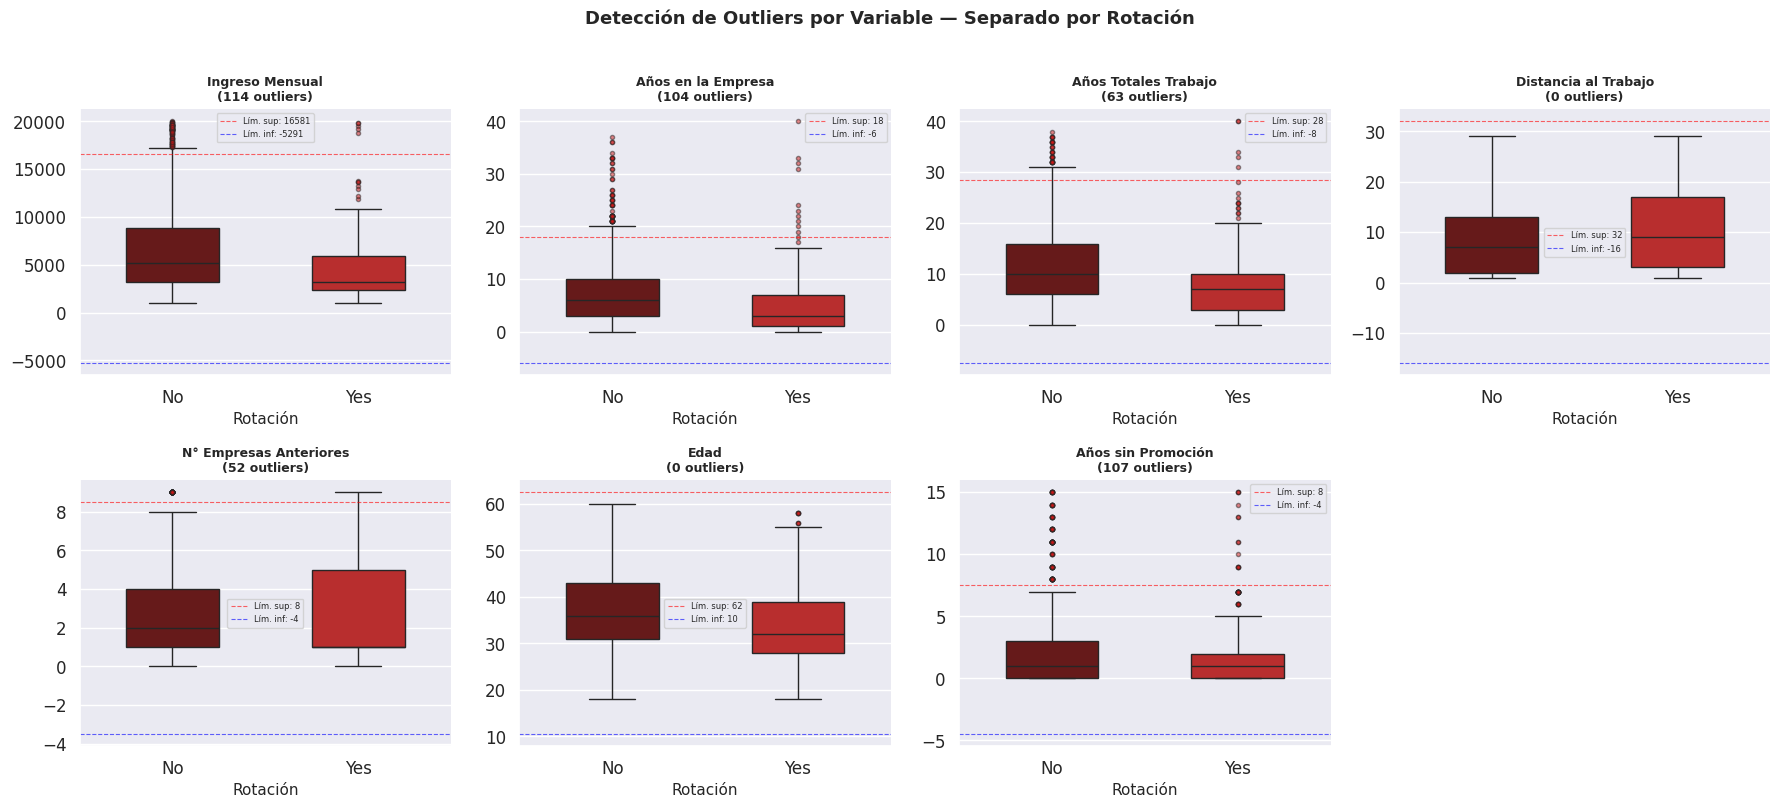

Guardado: fig_outliers_boxplot.png


In [ ]:
# GRÁFICO — Boxplots de variables con outliers

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

etiquetas_out = {
    'IngresoMensual'           : 'Ingreso Mensual',
    'AniosEnEmpresa'           : 'Años en la Empresa',
    'AniosTotalesTrabajo'      : 'Años Totales Trabajo',
    'DistanciaCasa'            : 'Distancia al Trabajo',
    'NumEmpresasTrabajadas'    : 'N° Empresas Anteriores',
    'Edad'                     : 'Edad',
    'AniosDesdeUltimaPromocion': 'Años sin Promoción'
}

for i, col in enumerate(vars_outliers):
    ax = axes[i]

    # Boxplot separado por grupo de rotación
    sns.boxplot(
        data=df_clean, x='Rotacion', y=col,
        palette=PALETA_ROTACION, ax=ax,
        order=['No', 'Yes'], width=0.5,
        flierprops=dict(marker='o', markerfacecolor=COLOR_ACENTO,
                        markersize=3, alpha=0.5)
    )

    # Límites IQR como líneas de referencia
    row = df_outliers_resumen[df_outliers_resumen['Variable'] == col].iloc[0]
    ax.axhline(row['Lim. Sup.'], color='red', linewidth=0.8,
               linestyle='--', alpha=0.6, label=f'Lím. sup: {row["Lim. Sup."]:.0f}')
    ax.axhline(row['Lim. Inf.'], color='blue', linewidth=0.8,
               linestyle='--', alpha=0.6, label=f'Lím. inf: {row["Lim. Inf."]:.0f}')

    n_out = int(row['N Outliers'])
    ax.set_title(f'{etiquetas_out[col]}\n({n_out} outliers)', fontsize=9, fontweight='bold')
    ax.set_xlabel('Rotación')
    ax.set_ylabel('')
    ax.legend(fontsize=6)
    sns.despine(ax=ax)

# Ocultar el subplot vacío (8vo)
axes[-1].set_visible(False)

fig.suptitle('Detección de Outliers por Variable — Separado por Rotación',
             fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig_outliers_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig_outliers_boxplot.png')

In [ ]:
# 4.9 RESUMEN FINAL DE LIMPIEZA Y PREPARACIÓN DE DATOS

print('RESUMEN FINAL — LIMPIEZA Y PREPARACIÓN DE DATOS')

print('\nDimensiones del Dataset')

print(f'Dataset original: {df.shape[0]} filas × {df.shape[1]} columnas')
print(f'Dataset limpio: {df_clean.shape[0]} filas × {df_clean.shape[1]} columnas')

print(f'\nFilas eliminadas    : {filas_eliminadas}')
print(f'Columnas eliminadas : {columnas_eliminadas}')


print('\nTransformaciones realizadas')

print('\n 1. Eliminación de columnas constantes')
print('• CantidadEmpleados')
print('• MayorDe18')
print('• HorasEstandar')

print('\n 2. Verificación y eliminación de filas duplicadas')

print('\n 3. Codificación de variables categóricas binarias')
print('• Rotacion → rotacion_num (Yes=1 / No=0)')
print('• HorasExtra → HorasExtra_num (Yes=1 / No=0)')

print('\n 4. Validación de tipos de datos')
print(f'• Variables numéricas   : {len(num_cols)}')
print(f'• Variables categóricas : {len(cat_cols)}')

print('\n 5. Verificación de rangos y valores imposibles')
print('• Edad')
print('• IngresoMensual')
print('• Variables ordinales de satisfacción')
print('• Antigüedad y experiencia laboral')

print('\n 6. Detección de valores atípicos (Outliers)')
print('• Método utilizado: IQR (Rango Intercuartílico)')

# Redefine vars_outliers if it's not already defined to avoid NameError
# This ensures the summary cell can run independently if previous cells were skipped or kernel reset.
if 'vars_outliers' not in locals() and 'vars_outliers' not in globals():
    vars_outliers = [
        'IngresoMensual',
        'AniosEnEmpresa',
        'AniosTotalesTrabajo',
        'DistanciaCasa',
        'NumEmpresasTrabajadas',
        'Edad',
        'AniosDesdeUltimaPromocion'
    ]

# Re-create df_outliers_resumen if it's not already defined
if 'df_outliers_resumen' not in locals() and 'df_outliers_resumen' not in globals():
    resumen_outliers = []
    for col in vars_outliers:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
        pct = n_out / len(df_clean) * 100
        resumen_outliers.append({
            'Variable': col,
            'Q1': Q1,
            'Q3': Q3,
            'IQR': IQR,
            'Lim. Inf.': lower,
            'Lim. Sup.': upper,
            'N Outliers': n_out,
            '% del total': round(pct, 2)
        })
    df_outliers_resumen = pd.DataFrame(resumen_outliers)

print(f'• Variables analizadas: {len(vars_outliers)}')

total_outliers = df_outliers_resumen['N Outliers'].sum()

var_mayor_out = (df_outliers_resumen.sort_values('N Outliers', ascending=False).iloc[0])

print(f'\n• Total de outliers detectados: {total_outliers}')

print(f'• Variable con más outliers:')
print(f'{var_mayor_out["Variable"]} ({int(var_mayor_out["N Outliers"])} casos)')

print('\nResultado Final')

print('El dataset quedó limpio, consistente y listo')
print('para el análisis exploratorio, pruebas')
print('estadísticas y modelos predictivos.')

print('\n' + '=' * 65)

RESUMEN FINAL — LIMPIEZA Y PREPARACIÓN DE DATOS

Dimensiones del Dataset
Dataset original: 1470 filas × 35 columnas
Dataset limpio: 1470 filas × 33 columnas

Filas eliminadas    : 0
Columnas eliminadas : 2

Transformaciones realizadas

 1. Eliminación de columnas constantes
• CantidadEmpleados
• MayorDe18
• HorasEstandar

 2. Verificación y eliminación de filas duplicadas

 3. Codificación de variables categóricas binarias
• Rotacion → rotacion_num (Yes=1 / No=0)
• HorasExtra → HorasExtra_num (Yes=1 / No=0)

 4. Validación de tipos de datos
• Variables numéricas   : 25
• Variables categóricas : 8

 5. Verificación de rangos y valores imposibles
• Edad
• IngresoMensual
• Variables ordinales de satisfacción
• Antigüedad y experiencia laboral

 6. Detección de valores atípicos (Outliers)
• Método utilizado: IQR (Rango Intercuartílico)
• Variables analizadas: 7

• Total de outliers detectados: 440
• Variable con más outliers:
IngresoMensual (114 casos)

Resultado Final
El dataset quedó lim

### Decisión sobre los valores atípicos detectados

| Variable | Outliers | Tipo | Decisión | Justificación |
|---|---|---|---|---|
| `IngresoMensual` | Sí (valores altos) | Casos reales válidos | **Conservar** | Representan ejecutivos y directivos con salarios altos. Eliminarlos distorsionaría el análisis de brecha salarial, que es uno de los hallazgos clave del proyecto. |
| `AniosEnEmpresa` | Sí (valores altos) | Casos reales válidos | **Conservar** | Empleados con alta antigüedad (> 30 años). Son parte natural de la distribución en una empresa consolidada. |
| `AniosTotalesTrabajo` | Sí (valores altos) | Casos reales válidos | **Conservar** | Igual que el caso anterior: empleados senior con larga trayectoria laboral. |
| `DistanciaCasa` | Sí (valores altos) | Casos reales válidos | **Conservar** | Algunos empleados viven lejos de la oficina. Es un factor de análisis relevante para la rotación, no un error. |
| `NumEmpresasTrabajadas` | Sí (valores altos) | Casos reales válidos | **Conservar** | Empleados con alta movilidad histórica. Es precisamente una variable asociada con mayor rotación. |
| `Edad` | No significativo | — | **Sin acción** | Los valores extremos están dentro del rango esperado para una población laboral activa. |
| `AniosDesdeUltimaPromocion` | Sí (valores altos) | Casos reales válidos | **Conservar** | Empleados sin ascenso por muchos años. Es un factor potencialmente asociado a insatisfacción y rotación. |

> **Conclusión:** ninguno de los outliers detectados corresponde a errores de captura o valores imposibles. Todos representan casos reales dentro del rango esperado para una empresa de tecnología. Se conservan en el dataset `df_clean` para no sesgar el análisis ni perder información relevante.
>
> Esta decisión es consistente con la verificación de rangos realizada en la **Sección 4.6**, donde todas las variables clave resultaron dentro de rangos válidos.

### Decisiones de limpieza documentadas

| # | Acción | Justificación |
|---|---|---|
| 1 | Eliminación de `CantidadEmpleados`, `MayorDe18`, `HorasEstandar` | Son columnas constantes: todos los empleados tienen el mismo valor. No aportan variabilidad ni información al análisis. |
| 2 | Eliminación de filas duplicadas | Registros idénticos duplicarían artificialmente datos de un mismo empleado. |
| 3 | Creación de `Rotacion_num` (0/1) | Permite calcular correlaciones y tasas de rotación con operaciones numéricas. La columna original se conserva para gráficos. |
| 4 | Creación de `HorasExtra_num` (0/1) | Igual que el caso anterior: facilita el análisis de correlación de esta variable con la rotación. |
| 5 | Verificación de rangos | Se confirmó que todas las variables clave están dentro de rangos válidos y esperados. No se detectaron valores imposibles ni errores de captura. |

> El dataset `df_clean` está listo para la **Sección 5 — Análisis Descriptivo**.

# Sección 5 — Análisis Descriptivo

En esta sección exploramos las variables del dataset agrupadas en tres bloques temáticos, siempre relacionándolas con la variable objetivo `Rotacion`:

| Bloque | Variables |
|---|---|
| **5.1 Demográficas** | Género, Estado Civil, Edad |
| **5.2 Laborales** | Departamento, Horas Extra, Ingreso Mensual, Años en la empresa |
| **5.3 Satisfacción** | Satisfacción laboral, Desempeño, Ambiente, Balance vida-trabajo |

> **Convención de color del proyecto:**
> - Azul (`#4C72B0`) → Empleados que **permanecen** (No)
> - Naranja (`#DD8452`) → Empleados que **rotan** (Yes)

## 5.1 Variables Demográficas

Analizamos cómo el **género**, el **estado civil** y la **edad** se relacionan con la rotación de empleados. Estas variables nos permiten identificar si existen perfiles demográficos con mayor tendencia a abandonar la organización.

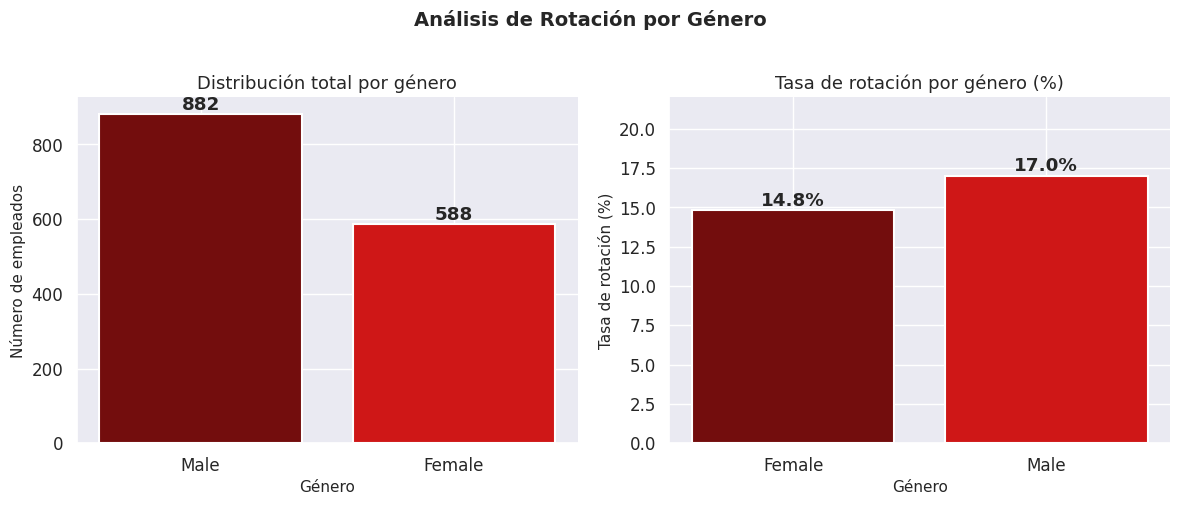


Guardado: fig_01_rotacion_genero.png
Tabla resumen:
Genero  Rotan  Total  Tasa (%)
Female     87    588      14.8
  Male    150    882      17.0


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
# GRÁFICO 5.1.1 — Rotación por Género

# Calculamos la tasa de rotación (%) por género
tasa_genero = (df_clean.groupby('Genero')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
tasa_genero['Tasa (%)'] = (tasa_genero['Rotan'] / tasa_genero['Total'] * 100).round(1)
tasa_genero = tasa_genero.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Distribución total por género
conteo_genero = df_clean['Genero'].value_counts()
axes[0].bar(conteo_genero.index, conteo_genero.values, color = [COLOR_PRINCIPAL, COLOR_ACENTO], edgecolor='white', linewidth=1.5)
for i, v in enumerate(conteo_genero.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')
axes[0].set_title('Distribución total por género')
axes[0].set_ylabel('Número de empleados')
axes[0].set_xlabel('Género')
sns.despine(ax=axes[0])

# Subplot 2: Tasa de rotación por género
bars = axes[1].bar(tasa_genero['Genero'], tasa_genero['Tasa (%)'], color=[COLOR_PRINCIPAL, COLOR_ACENTO], edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, tasa_genero['Tasa (%)']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val}%', ha='center', fontweight='bold')

axes[1].set_title('Tasa de rotación por género (%)')
axes[1].set_ylabel('Tasa de rotación (%)')
axes[1].set_xlabel('Género')
axes[1].set_ylim(0,tasa_genero['Tasa (%)'].max() + 5)
sns.despine(ax=axes[1])

fig.suptitle('Análisis de Rotación por Género', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_01_rotacion_genero.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print('Guardado: fig_01_rotacion_genero.png')
print('Tabla resumen:')
print(tasa_genero[['Genero', 'Rotan', 'Total', 'Tasa (%)']].to_string(index=False))

**Interpretación — Género:**


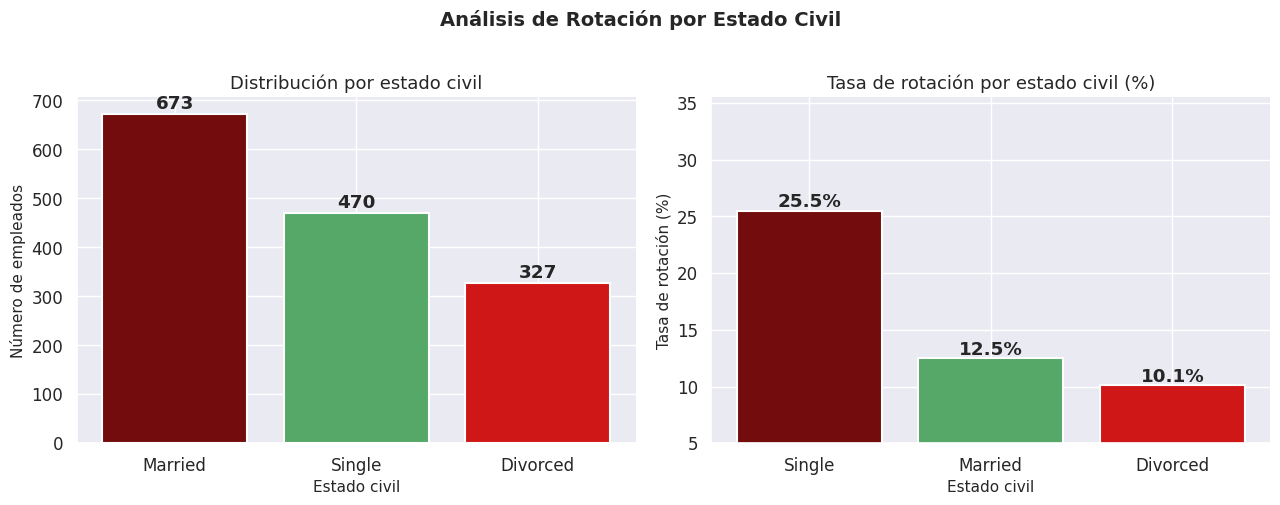

Guardado: fig_02_rotacion_estado_civil.png

 Tabla resumen:
EstadoCivil  Rotan  Total  Tasa (%)
     Single    120    470      25.5
    Married     84    673      12.5
   Divorced     33    327      10.1


In [ ]:
# GRÁFICO 5.1.2 — Rotación por Estado Civil

tasa_civil = (df_clean.groupby('EstadoCivil')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
tasa_civil['Tasa (%)'] = (tasa_civil['Rotan'] / tasa_civil['Total'] * 100).round(1)
tasa_civil = tasa_civil.reset_index().sort_values('Tasa (%)', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Distribución por estado civil
conteo_civil = df_clean['EstadoCivil'].value_counts()
colores_civil = [COLOR_PRINCIPAL, '#55A868', COLOR_ACENTO]
axes[0].bar(conteo_civil.index, conteo_civil.values, color=colores_civil, edgecolor='white', linewidth=1.5)
for i, v in enumerate(conteo_civil.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')
axes[0].set_title('Distribución por estado civil')
axes[0].set_ylabel('Número de empleados')
axes[0].set_xlabel('Estado civil')
sns.despine(ax=axes[0])

# Subplot 2: Tasa de rotación por estado civil
palette_civil = [COLOR_PRINCIPAL,'#55A868',COLOR_ACENTO]
bars = axes[1].bar(tasa_civil['EstadoCivil'], tasa_civil['Tasa (%)'], color=palette_civil, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, tasa_civil['Tasa (%)']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val}%', ha='center', fontweight='bold')
axes[1].set_title('Tasa de rotación por estado civil (%)')
axes[1].set_ylabel('Tasa de rotación (%)')
axes[1].set_xlabel('Estado civil')
axes[1].set_ylim(5,tasa_civil['Tasa (%)'].max() + 10)
sns.despine(ax=axes[1])

fig.suptitle('Análisis de Rotación por Estado Civil', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_02_rotacion_estado_civil.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig_02_rotacion_estado_civil.png')
print('\n Tabla resumen:')
print(tasa_civil[['EstadoCivil', 'Rotan', 'Total', 'Tasa (%)']].to_string(index=False))

**Interpretación — Estado Civil:**


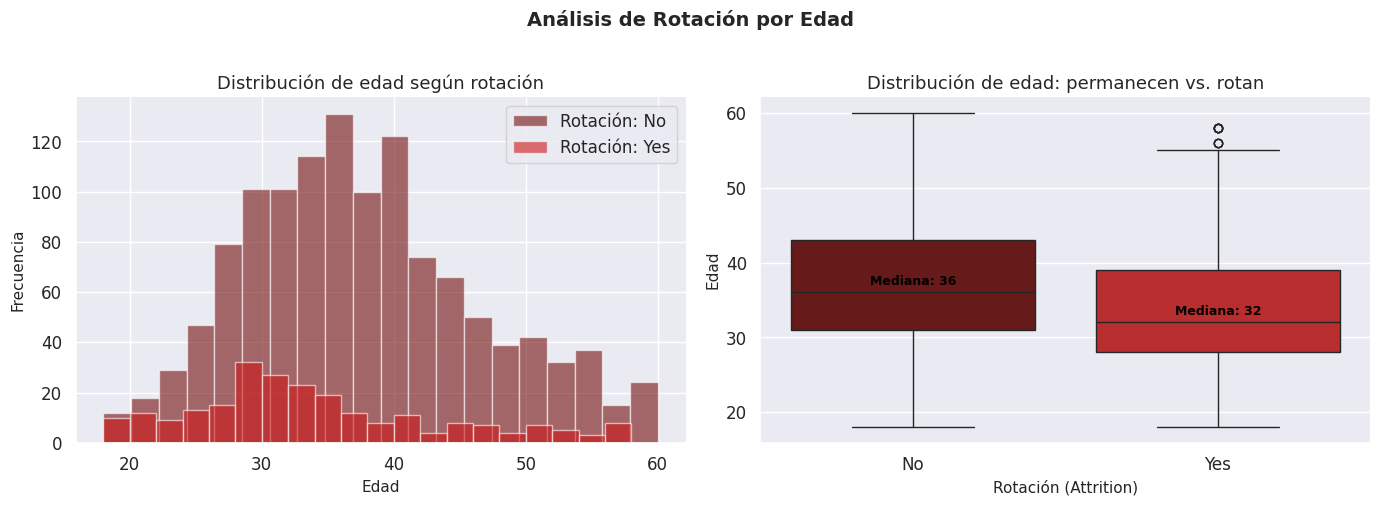


 Guardado: fig_03_rotacion_edad.png

 Estadísticos de edad por grupo:
          Media  Mediana  Desv. Std
Rotacion                           
No         37.6     36.0        8.9
Yes        33.6     32.0        9.7


In [ ]:
# GRÁFICO 5.1.3 — Distribución de Edad por Rotación

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Histograma de edad por grupo de rotación (superpuesto)
for grupo, color in PALETA_ROTACION.items():
    subset = df_clean[df_clean['Rotacion'] == grupo]['Edad']
    axes[0].hist(subset, bins=20, alpha=0.6, color=color, label=f'Rotación: {grupo}', edgecolor='white')
axes[0].set_title('Distribución de edad según rotación')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()
sns.despine(ax=axes[0])

# Subplot 2: Boxplot de edad por rotación
sns.boxplot(data=df_clean, x='Rotacion', y='Edad', palette=PALETA_ROTACION, ax=axes[1], order=['No', 'Yes'])
axes[1].set_title('Distribución de edad: permanecen vs. rotan')
axes[1].set_xlabel('Rotación (Attrition)')
axes[1].set_ylabel('Edad')

# Agregar mediana como anotación
for i, grupo in enumerate(['No', 'Yes']):
    med = df_clean[df_clean['Rotacion'] == grupo]['Edad'].median()
    axes[1].text(i, med + 1, f'Mediana: {med:.0f}', ha='center', fontsize=9, color='black', fontweight='bold')
sns.despine(ax=axes[1])

fig.suptitle('Análisis de Rotación por Edad', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_03_rotacion_edad.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print(' Guardado: fig_03_rotacion_edad.png')

# Estadísticos por grupo
print('\n Estadísticos de edad por grupo:')
print(df_clean.groupby('Rotacion')['Edad'] .agg(['mean', 'median', 'std']).round(1).rename(columns={'mean': 'Media', 'median': 'Mediana', 'std': 'Desv. Std'}))

## 5.2 Variables Laborales

Analizamos factores del entorno de trabajo: **departamento**, **horas extra**, **ingreso mensual** y **años en la empresa**. Estas variables suelen tener alta capacidad explicativa sobre la decisión de renuncia.

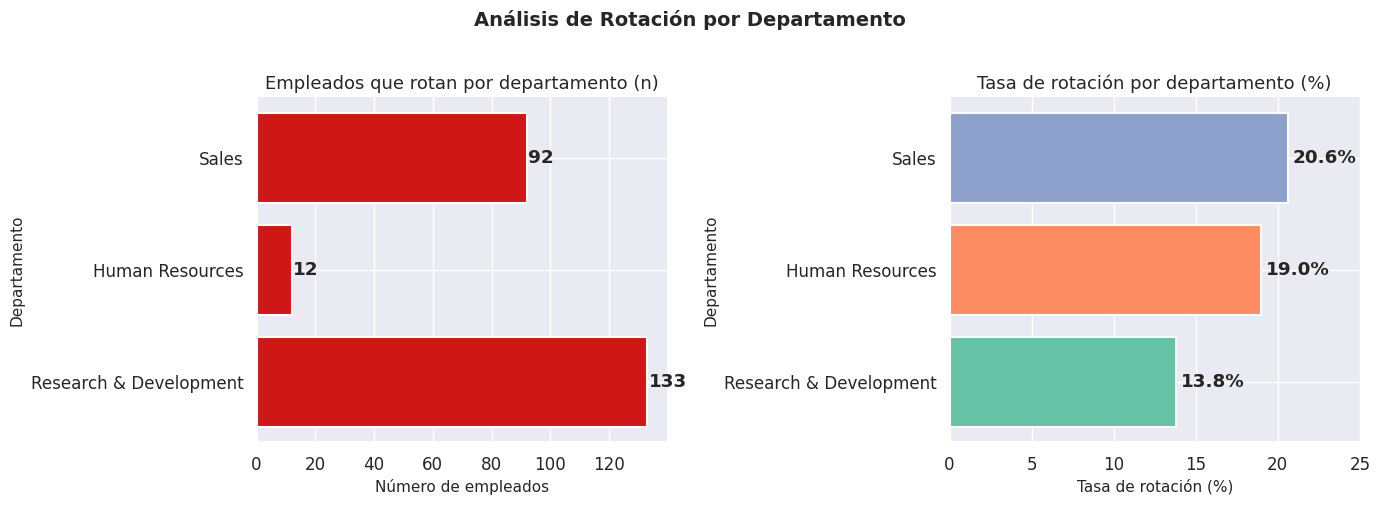


 Guardado: fig_04_rotacion_departamento.png

 Tabla resumen:
          Departamento  Rotan  Total  Tasa (%)
Research & Development    133    961      13.8
       Human Resources     12     63      19.0
                 Sales     92    446      20.6


In [ ]:
# GRÁFICO 5.2.1 — Rotación por Departamento

tasa_dept = (df_clean.groupby('Departamento')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
tasa_dept['Tasa (%)'] = (tasa_dept['Rotan'] / tasa_dept['Total'] * 100).round(1)
tasa_dept = tasa_dept.reset_index().sort_values('Tasa (%)', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Cantidad de empleados que rotan por departamento
colores_dept = sns.color_palette('Set2', n_colors=3)
axes[0].barh(tasa_dept['Departamento'], tasa_dept['Rotan'], color=COLOR_ACENTO, edgecolor='white', linewidth=1.5)
for i, v in enumerate(tasa_dept['Rotan']):
    axes[0].text(v + 0.5, i, str(v), va='center', fontweight='bold')
axes[0].set_title('Empleados que rotan por departamento (n)')
axes[0].set_xlabel('Número de empleados')
axes[0].set_ylabel('Departamento')
sns.despine(ax=axes[0])

# Subplot 2: Tasa de rotación por departamento (%)
bars = axes[1].barh(tasa_dept['Departamento'], tasa_dept['Tasa (%)'], color=colores_dept, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, tasa_dept['Tasa (%)']):
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2, f'{val}%', va='center', fontweight='bold')
axes[1].set_title('Tasa de rotación por departamento (%)')
axes[1].set_xlabel('Tasa de rotación (%)')
axes[1].set_ylabel('Departamento')
axes[1].set_xlim(0, 25)
sns.despine(ax=axes[1])

fig.suptitle('Análisis de Rotación por Departamento', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_04_rotacion_departamento.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print(' Guardado: fig_04_rotacion_departamento.png')
print('\n Tabla resumen:')
print(tasa_dept[['Departamento', 'Rotan', 'Total', 'Tasa (%)']].to_string(index=False))

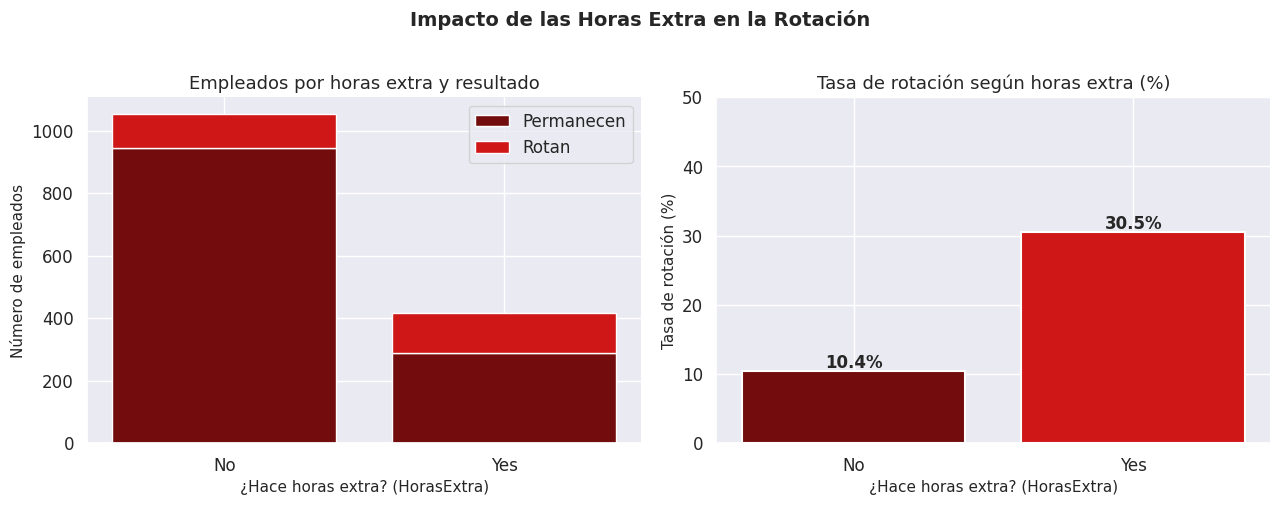


Guardado: fig_05_rotacion_overtime.png

 Tabla resumen:
HorasExtra  Rotan  Total  Tasa (%)
        No    110   1054      10.4
       Yes    127    416      30.5


In [ ]:
# GRÁFICO 5.2.2 — Rotación según Horas Extra (OverTime)

tasa_ot = (df_clean.groupby('HorasExtra')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
tasa_ot['Permanecen'] = tasa_ot['Total'] - tasa_ot['Rotan']
tasa_ot['Tasa (%)'] = (tasa_ot['Rotan'] / tasa_ot['Total'] * 100).round(1)
tasa_ot = tasa_ot.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Barras apiladas (permanecen vs. rotan por grupo HorasExtra)
x = range(len(tasa_ot))
axes[0].bar(x, tasa_ot['Permanecen'], label='Permanecen', color=COLOR_PRINCIPAL, edgecolor='white')
axes[0].bar(x, tasa_ot['Rotan'], bottom=tasa_ot['Permanecen'], label='Rotan', color=COLOR_ACENTO, edgecolor='white')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(tasa_ot['HorasExtra'])
axes[0].set_title('Empleados por horas extra y resultado')
axes[0].set_ylabel('Número de empleados')
axes[0].set_xlabel('¿Hace horas extra? (HorasExtra)')
axes[0].legend()
sns.despine(ax=axes[0])

# Subplot 2: Tasa de rotación
bars = axes[1].bar(tasa_ot['HorasExtra'], tasa_ot['Tasa (%)'], color=[COLOR_PRINCIPAL, COLOR_ACENTO], edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, tasa_ot['Tasa (%)']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val}%', ha='center', fontweight='bold', fontsize=12)
axes[1].set_title('Tasa de rotación según horas extra (%)')
axes[1].set_ylabel('Tasa de rotación (%)')
axes[1].set_xlabel('¿Hace horas extra? (HorasExtra)')
axes[1].set_ylim(0, 50)
sns.despine(ax=axes[1])

fig.suptitle('Impacto de las Horas Extra en la Rotación', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_05_rotacion_overtime.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print('Guardado: fig_05_rotacion_overtime.png')
print('\n Tabla resumen:')
print(tasa_ot[['HorasExtra', 'Rotan', 'Total', 'Tasa (%)']].to_string(index=False))

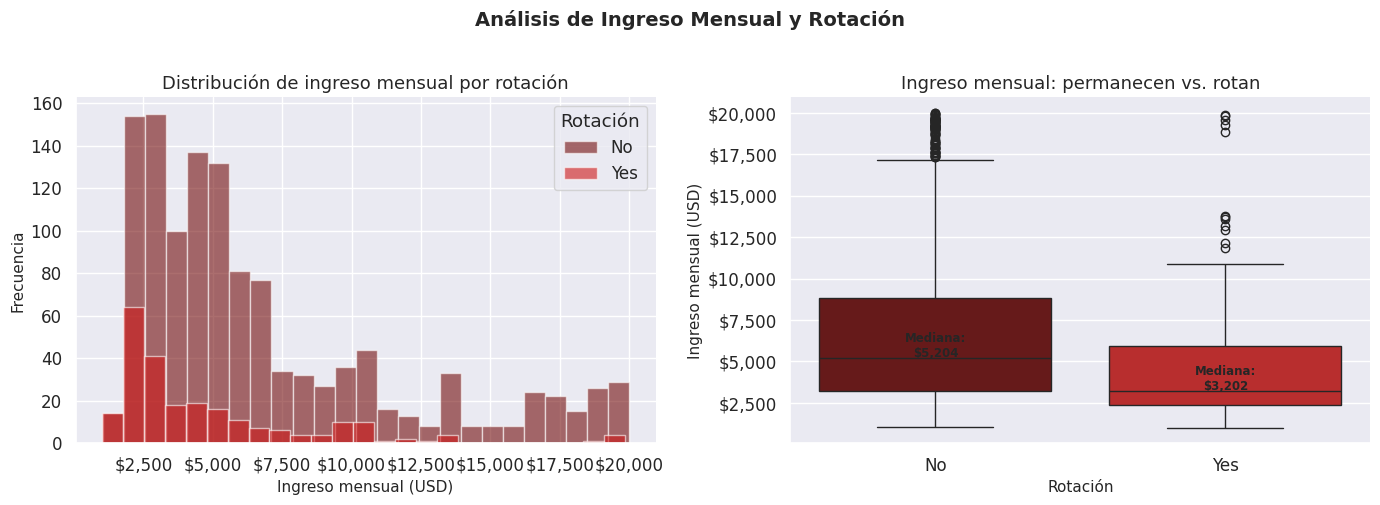

 Guardado: fig_06_rotacion_salario.png

 Estadísticos de ingreso mensual por grupo:
           Media  Mediana  Desv. Std  Mínimo  Máximo
Rotacion                                            
No        6833.0   5204.0     4818.0    1051   19999
Yes       4787.0   3202.0     3640.0    1009   19859


In [ ]:
# GRÁFICO 5.2.3 — Distribución de Ingreso Mensual por Rotación

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Histograma superpuesto
for grupo, color in PALETA_ROTACION.items():
    subset = df_clean[df_clean['Rotacion'] == grupo]['IngresoMensual']
    axes[0].hist(subset, bins=25, alpha=0.6, color=color, label=f'{grupo}', edgecolor='white')
axes[0].set_title('Distribución de ingreso mensual por rotación')
axes[0].set_xlabel('Ingreso mensual (USD)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend(title='Rotación')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
sns.despine(ax=axes[0])

# Subplot 2: Boxplot comparativo
sns.boxplot(data=df_clean, x='Rotacion', y='IngresoMensual', palette=PALETA_ROTACION, ax=axes[1], order=['No', 'Yes'])
axes[1].set_title('Ingreso mensual: permanecen vs. rotan')
axes[1].set_xlabel('Rotación')
axes[1].set_ylabel('Ingreso mensual (USD)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# Mediana anotada
for i, grupo in enumerate(['No', 'Yes']):
    med = df_clean[df_clean['Rotacion'] == grupo]['IngresoMensual'].median()
    axes[1].text(i, med + 100, f'Mediana:\n${med:,.0f}', ha='center', fontsize=8.5, fontweight='bold')
sns.despine(ax=axes[1])

fig.suptitle('Análisis de Ingreso Mensual y Rotación', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_06_rotacion_salario.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Guardado: fig_06_rotacion_salario.png')

print('\n Estadísticos de ingreso mensual por grupo:')
print(df_clean.groupby('Rotacion')['IngresoMensual']
      .agg(['mean', 'median', 'std', 'min', 'max'])
      .round(0)
      .rename(columns={'mean': 'Media', 'median': 'Mediana','std': 'Desv. Std', 'min': 'Mínimo', 'max': 'Máximo'}))

**Interpretación — Ingreso Mensual:**
*(Completar: comparar la mediana salarial entre grupos. ¿Los empleados que rotan ganan en promedio menos que los que permanecen? ¿La distribución salarial es similar o muy diferente entre grupos?)*

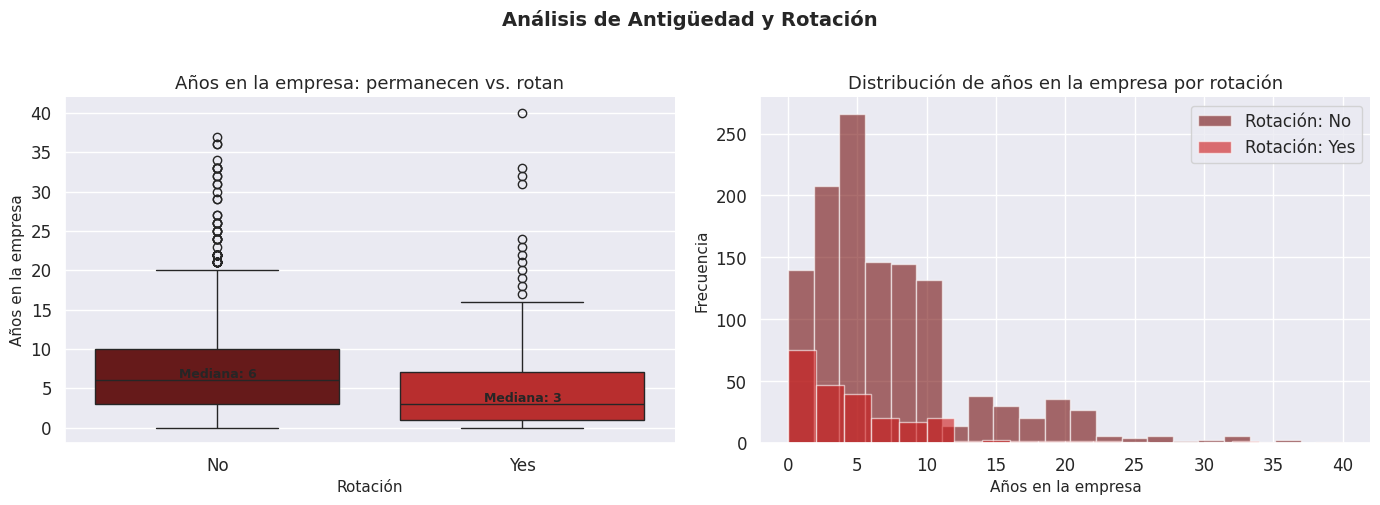


 Guardado: fig_07_rotacion_antiguedad.png

 Estadísticos de años en la empresa por grupo:
          Media  Mediana  Desv. Std
Rotacion                           
No          7.4      6.0        6.1
Yes         5.1      3.0        5.9


In [ ]:
# GRÁFICO 5.2.4 — Años en la Empresa por Rotación

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Boxplot
sns.boxplot(data=df_clean, x='Rotacion', y='AniosEnEmpresa',
            palette=PALETA_ROTACION, ax=axes[0], order=['No', 'Yes'])
axes[0].set_title('Años en la empresa: permanecen vs. rotan')
axes[0].set_xlabel('Rotación')
axes[0].set_ylabel('Años en la empresa')
for i, grupo in enumerate(['No', 'Yes']):
    med = df_clean[df_clean['Rotacion'] == grupo]['AniosEnEmpresa'].median()
    axes[0].text(i, med + 0.3, f'Mediana: {med:.0f}', ha='center', fontsize=9, fontweight='bold')
sns.despine(ax=axes[0])

# Subplot 2: Histograma por grupo
for grupo, color in PALETA_ROTACION.items():
    subset = df_clean[df_clean['Rotacion'] == grupo]['AniosEnEmpresa']
    axes[1].hist(subset, bins=20, alpha=0.6, color=color, label=f'Rotación: {grupo}', edgecolor='white')
axes[1].set_title('Distribución de años en la empresa por rotación')
axes[1].set_xlabel('Años en la empresa')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()
sns.despine(ax=axes[1])

fig.suptitle('Análisis de Antigüedad y Rotación', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_07_rotacion_antiguedad.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print(' Guardado: fig_07_rotacion_antiguedad.png')

print('\n Estadísticos de años en la empresa por grupo:')
print(df_clean.groupby('Rotacion')['AniosEnEmpresa']
      .agg(['mean', 'median', 'std'])
      .round(1)
      .rename(columns={'mean': 'Media', 'median': 'Mediana', 'std': 'Desv. Std'}))

**Interpretación — Años en la empresa:**
*(Completar: ¿Los empleados con menos antigüedad rotan más? ¿Existe un período crítico de vulnerabilidad en los primeros años? Esto tiene implicaciones directas en políticas de onboarding y retención temprana.)*

---
## 5.3 Variables de Satisfacción y Desempeño

Analizamos variables ordinales (escala 1–4) que miden la percepción subjetiva de los empleados sobre su trabajo, ambiente y equilibrio de vida. Son indicadores clave del bienestar laboral y se espera que tengan relación inversa con la rotación.

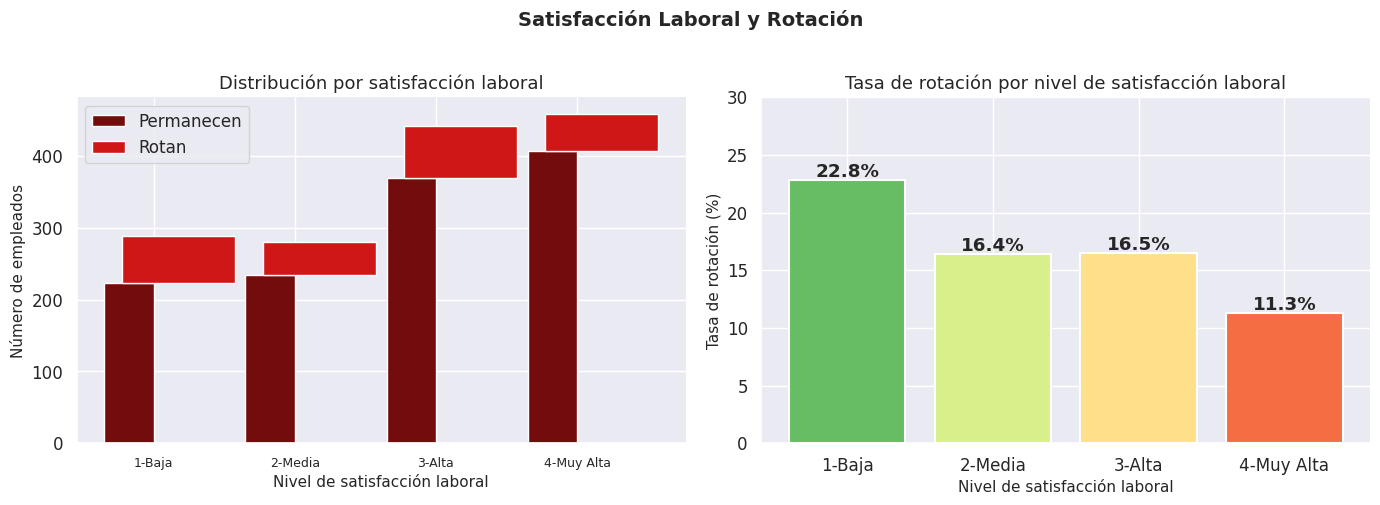


 Guardado: fig_08_rotacion_jobsatisfaction.png

 Tabla resumen:
     Nivel  Rotan  Total  Tasa (%)
    1-Baja     66    289      22.8
   2-Media     46    280      16.4
    3-Alta     73    442      16.5
4-Muy Alta     52    459      11.3


In [ ]:
# GRÁFICO 5.3.1 — Satisfacción Laboral (JobSatisfaction) vs Rotación

# Mapa de etiquetas para las escalas ordinales
label_satisf = {1: '1-Baja', 2: '2-Media', 3: '3-Alta', 4: '4-Muy Alta'}

df_clean['JobSatisfaction_label'] = df_clean['SatisfaccionLaboral'].map(label_satisf)

tasa_js = (df_clean.groupby('SatisfaccionLaboral')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
tasa_js['Tasa (%)'] = (tasa_js['Rotan'] / tasa_js['Total'] * 100).round(1)
tasa_js = tasa_js.reset_index()
tasa_js['Nivel'] = tasa_js['SatisfaccionLaboral'].map(label_satisf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Barras agrupadas (permanecen vs. rotan por nivel)
x = np.arange(len(tasa_js))
width = 0.35
permanecen = tasa_js['Total'] - tasa_js['Rotan']
axes[0].bar(x - width/2, permanecen, width, label='Permanecen',color=COLOR_PRINCIPAL, edgecolor='white')
axes[0].bar(x + width/2, tasa_js['Rotan'], bottom=permanecen, label='Rotan', color=COLOR_ACENTO, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(tasa_js['Nivel'], fontsize=9)
axes[0].set_title('Distribución por satisfacción laboral')
axes[0].set_ylabel('Número de empleados')
axes[0].set_xlabel('Nivel de satisfacción laboral')
axes[0].legend()
sns.despine(ax=axes[0])

# Subplot 2: Tasa de rotación por nivel
colores_js = sns.color_palette('RdYlGn', n_colors=4)[::-1]
bars = axes[1].bar(tasa_js['Nivel'], tasa_js['Tasa (%)'], color=colores_js, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, tasa_js['Tasa (%)']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val}%', ha='center', fontweight='bold')
axes[1].set_title('Tasa de rotación por nivel de satisfacción laboral')
axes[1].set_ylabel('Tasa de rotación (%)')
axes[1].set_xlabel('Nivel de satisfacción laboral')
axes[1].set_ylim(0, 30)
sns.despine(ax=axes[1])

fig.suptitle('Satisfacción Laboral y Rotación', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_08_rotacion_jobsatisfaction.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print(' Guardado: fig_08_rotacion_jobsatisfaction.png')
print('\n Tabla resumen:')
print(tasa_js[['Nivel', 'Rotan', 'Total', 'Tasa (%)']].to_string(index=False))

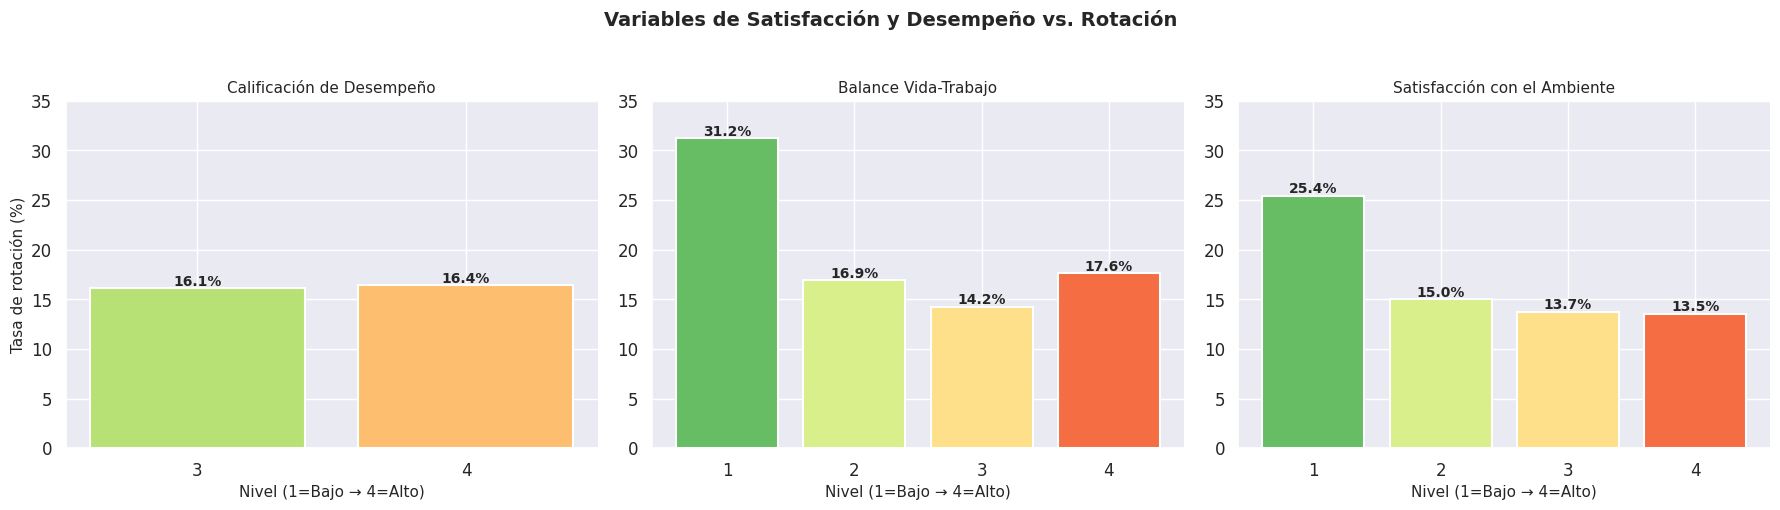


 Guardado: fig_09_panel_satisfaccion.png


In [ ]:
# GRÁFICO 5.3.2 — Panel: 3 variables de satisfacción vs Rotación

variables_satisf = {
    'EvaluacionRendimiento'   : 'Calificación de Desempeño',
    'EquilibrioTrabajoVida'   : 'Balance Vida-Trabajo',
    'SatisfaccionAmbiente'    : 'Satisfacción con el Ambiente'
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (col, titulo) in zip(axes, variables_satisf.items()):
    tasa = (df_clean.groupby(col)['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
    tasa['Tasa (%)'] = (tasa['Rotan'] / tasa['Total'] * 100).round(1)
    tasa = tasa.reset_index()

    colores = sns.color_palette('RdYlGn', n_colors=len(tasa))[::-1]
    bars = ax.bar(tasa[col].astype(str), tasa['Tasa (%)'], color=colores, edgecolor='white', linewidth=1.5)
    for bar, val in zip(bars, tasa['Tasa (%)']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val}%', ha='center', fontweight='bold', fontsize=10)
    ax.set_title(titulo, fontsize=11)
    ax.set_ylabel('Tasa de rotación (%)' if ax == axes[0] else '')
    ax.set_xlabel('Nivel (1=Bajo → 4=Alto)')
    ax.set_ylim(0, 35)
    sns.despine(ax=ax)

fig.suptitle('Variables de Satisfacción y Desempeño vs. Rotación', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_09_panel_satisfaccion.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print(' Guardado: fig_09_panel_satisfaccion.png')

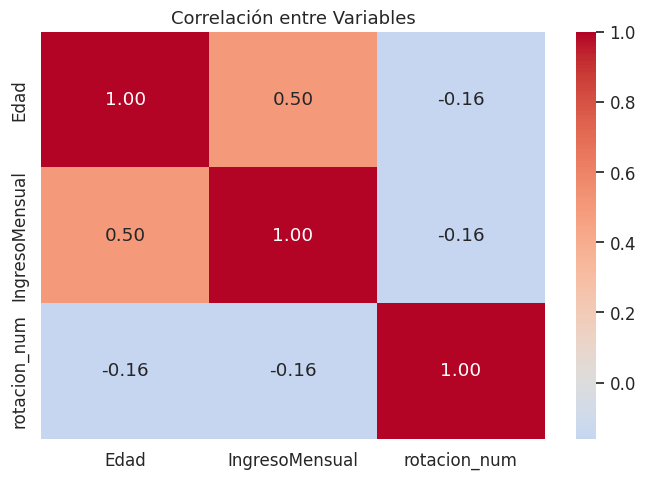


Conclusiones iniciales

Edad promedio empleados que rotan: 33.6
Edad promedio empleados que permanecen: 37.6

Salario promedio empleados que rotan: $4,787
Salario promedio empleados que permanecen: $6,833

Revisar especialmente:
- Empleados jóvenes
- Empleados con horas extra
- Empleados con salario bajo
- Empleados solteros


In [ ]:
# 5.4 Matriz de Correlación

# Variables numéricas para correlación
corr = df_clean[ [
        'Edad',
        'IngresoMensual',
        'rotacion_num'
    ]].corr()

plt.figure(figsize=(7,5))

sns.heatmap(corr,annot=True,cmap='coolwarm', center=0,fmt='.2f')

plt.title('Correlación entre Variables')
plt.tight_layout()
plt.show()
print()

print('Conclusiones iniciales')

edad_rotan = df_clean[df_clean['Rotacion']=='Yes']['Edad'].mean()
edad_no = df_clean[df_clean['Rotacion']=='No']['Edad'].mean()

salario_rotan = df_clean[df_clean['Rotacion']=='Yes']['IngresoMensual'].mean()
salario_no = df_clean[df_clean['Rotacion']=='No']['IngresoMensual'].mean()

print(f'\nEdad promedio empleados que rotan: {edad_rotan:.1f}')
print(f'Edad promedio empleados que permanecen: {edad_no:.1f}')

print(f'\nSalario promedio empleados que rotan: ${salario_rotan:,.0f}')
print(f'Salario promedio empleados que permanecen: ${salario_no:,.0f}')

print('\nRevisar especialmente:')
print('- Empleados jóvenes')
print('- Empleados con horas extra')
print('- Empleados con salario bajo')
print('- Empleados solteros')

In [ ]:
# T-TEST: COMPARACIÓN DE MEDIAS SEGÚN ROTACIÓN
from scipy.stats import ttest_ind

# Variables numéricas a evaluar
variables_numericas_test = [
    'Edad',
    'IngresoMensual',
    'SatisfaccionLaboral',
    'AniosEnEmpresa'
]

print("Resultados T-TEST \n")

for variable in variables_numericas_test:

    # Grupo empleados que NO rotan
    grupo_0 = df_clean[df_clean['rotacion_num'] == 0][variable]

    # Grupo empleados que SÍ rotan
    grupo_1 = df_clean[df_clean['rotacion_num'] == 1][variable]

    # Prueba T
    t_stat, p_value = ttest_ind(grupo_0, grupo_1)

    print(f"Variable: {variable}")
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {p_value:.4f}")

    # Interpretación
    if p_value < 0.05:
        print("Resultado: Existe diferencia significativa.\n")
    else:
        print("Resultado: No existe diferencia significativa.\n")

Resultados T-TEST 

Variable: Edad
T-statistic: 6.1787
P-value: 0.0000
Resultado: Existe diferencia significativa.

Variable: IngresoMensual
T-statistic: 6.2039
P-value: 0.0000
Resultado: Existe diferencia significativa.

Variable: SatisfaccionLaboral
T-statistic: 3.9862
P-value: 0.0001
Resultado: Existe diferencia significativa.

Variable: AniosEnEmpresa
T-statistic: 5.1963
P-value: 0.0000
Resultado: Existe diferencia significativa.



In [ ]:
# ANOVA

from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("Resultados Anova\n")

# ANOVA: INGRESO MENSUAL POR DEPARTAMENTO
grupos_departamento = []

for grupo in df_clean['Departamento'].unique():
    datos = df_clean[df_clean['Departamento'] == grupo]['IngresoMensual']
    grupos_departamento.append(datos)

# ANOVA
f_stat, p_value = f_oneway(*grupos_departamento)

print("IngresoMensual vs Departamento")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Resultado: Existen diferencias significativas.\n")
else:
    print("Resultado: No existen diferencias significativas.\n")


# ANOVA: Satisfacción Laboral por Rol

grupos_rol = []

for grupo in df_clean['RolLaboral'].unique():
    datos = df_clean[df_clean['RolLaboral'] == grupo]['SatisfaccionLaboral']
    grupos_rol.append(datos)

# ANOVA
f_stat, p_value = f_oneway(*grupos_rol)

print("SatisfaccionLaboral vs RolLaboral")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Resultado: Existen diferencias significativas.\n")
else:
    print("Resultado: No existen diferencias significativas.\n")

Resultados Anova

IngresoMensual vs Departamento
F-statistic: 3.2018
P-value: 0.0410
Resultado: Existen diferencias significativas.

SatisfaccionLaboral vs RolLaboral
F-statistic: 0.3652
P-value: 0.9390
Resultado: No existen diferencias significativas.



## Tabla Resumen de Tasas de Rotación por Variable

Esta tabla consolida los hallazgos principales de la Sección 5 para facilitar la comparación y la escritura del informe.

In [ ]:
# TABLA RESUMEN GENERAL — Tasas de rotación por categoría

print('Resumen General — Tasas De Rotación Por Variable')

variables_cat = {
    'Género'         : 'Genero',
    'Estado Civil'   : 'EstadoCivil',
    'Departamento'   : 'Departamento',
    'Horas Extra'    : 'HorasExtra',
}

for nombre, col in variables_cat.items():
    tasa = (df_clean.groupby(col)['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
    tasa['Tasa (%)'] = (tasa['Rotan'] / tasa['Total'] * 100).round(1)
    print(f'\n  {nombre}:')
    for idx, row in tasa.iterrows():
        print(f'{idx:<20} {row["Rotan"]:>3} de {row["Total"]:>4}  ({row["Tasa (%)"]:.1f}%)')

print()
print('Estadísticos Numéricos Por Grupo De Rotación')

vars_num = ['Edad', 'IngresoMensual', 'AniosEnEmpresa', 'SatisfaccionLaboral', 'EquilibrioTrabajoVida', 'SatisfaccionAmbiente']
print()
print(df_clean.groupby('Rotacion')[vars_num].mean().round(2).T.rename(columns={'No': 'Permanecen (media)', 'Yes': 'Rotan (media)'}).to_string())

Resumen General — Tasas De Rotación Por Variable

  Género:
Female               87.0 de 588.0  (14.8%)
Male                 150.0 de 882.0  (17.0%)

  Estado Civil:
Divorced             33.0 de 327.0  (10.1%)
Married              84.0 de 673.0  (12.5%)
Single               120.0 de 470.0  (25.5%)

  Departamento:
Human Resources      12.0 de 63.0  (19.0%)
Research & Development 133.0 de 961.0  (13.8%)
Sales                92.0 de 446.0  (20.6%)

  Horas Extra:
No                   110.0 de 1054.0  (10.4%)
Yes                  127.0 de 416.0  (30.5%)

Estadísticos Numéricos Por Grupo De Rotación

Rotacion               Permanecen (media)  Rotan (media)
Edad                                37.56          33.61
IngresoMensual                    6832.74        4787.09
AniosEnEmpresa                       7.37           5.13
SatisfaccionLaboral                  2.78           2.47
EquilibrioTrabajoVida                2.78           2.66
SatisfaccionAmbiente                 2.77           2.

# Secciones 6 y 7 — Correlaciones y Segmentación por Departamento

En estas dos secciones respondemos la parte más profunda de la pregunta de investigación:

> *¿Cuáles factores presentan la **relación más fuerte** con la rotación, y cómo varía esa relación **según departamento**?*

| Sección | Qué responde |
|---|---|
| **6 — Correlaciones** | ¿Qué variables numéricas tienen mayor asociación con `Rotacion`? |
| **7 — Segmentación** | ¿Cómo se comportan OverTime, salario y satisfacción dentro de cada departamento? |

---
## Sección 6 — Análisis de Correlaciones

El análisis de correlaciones nos permite identificar qué variables numéricas tienen una **asociación estadística** con la rotación (`rotacion_num`). Usamos el coeficiente de correlación de Pearson:

- Valores **cercanos a +1** → correlación positiva (a mayor X, mayor rotación)
- Valores **cercanos a -1** → correlación negativa (a mayor X, menor rotación)
- Valores **cercanos a 0** → poca asociación lineal

> **Importante:** correlación no implica causalidad. Describimos asociaciones, no causas.

In [ ]:
# 6.1 SELECCIÓN DE VARIABLES PARA LA MATRIZ DE CORRELACIÓN

vars_correlacion = [
    'rotacion_num',
    'Edad',
    'IngresoMensual',
    'AniosEnEmpresa',
    'AniosEnRolActual',
    'AniosDesdeUltimaPromocion',
    'AniosConGerenteActual',
    'AniosTotalesTrabajo',
    'HorasExtra_num',
    'SatisfaccionLaboral',
    'SatisfaccionAmbiente',
    'EquilibrioTrabajoVida',
    'EvaluacionRendimiento',
    'InvolucramientoLaboral',
    'NivelLaboral',
    'NumEmpresasTrabajadas',
    'DistanciaCasa',
    'AumentoPorcentualSalario',
    'VecesEntrenamientoUltimoAnio'
]

df_corr = df_clean[vars_correlacion].copy()
print(f'{len(vars_correlacion)} variables seleccionadas para correlación.')

19 variables seleccionadas para correlación.


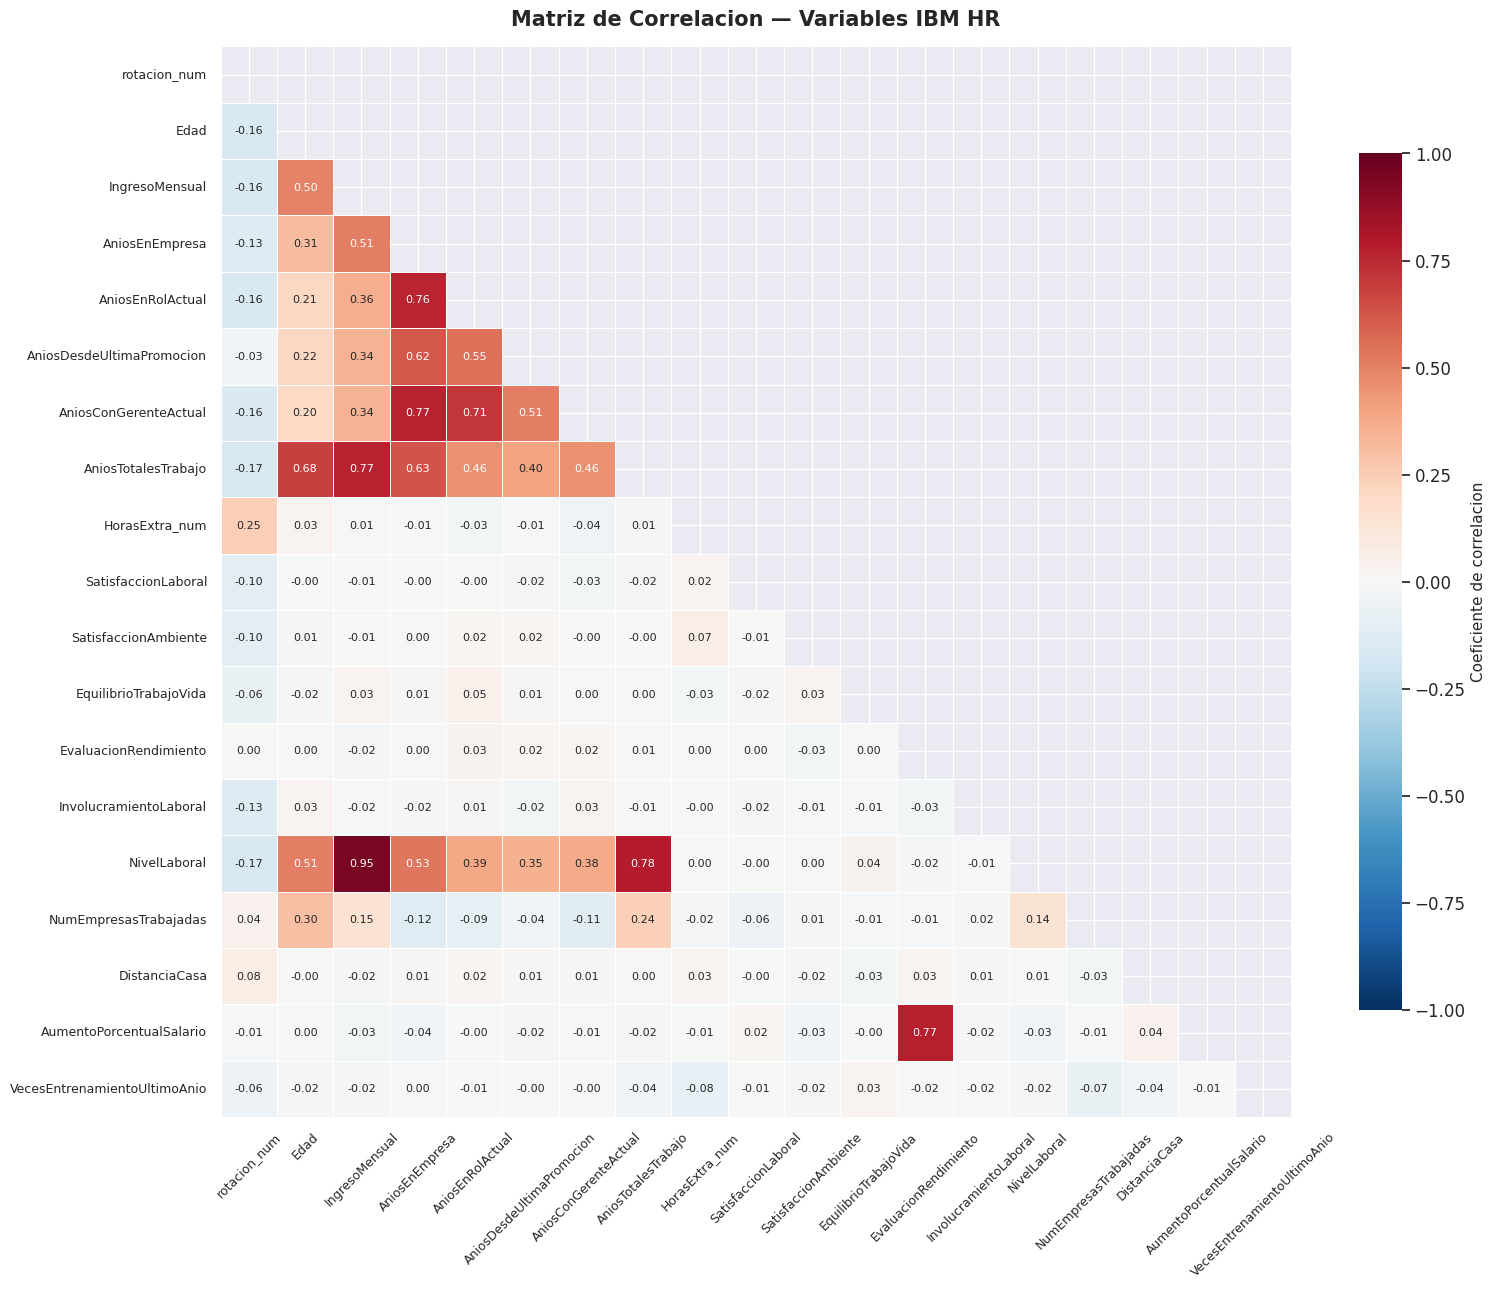


 Guardado: fig_10_heatmap_correlacion.png


In [ ]:
# GRÁFICO 6.1 — Mapa de Correlaciones

matriz_corr = df_corr.corr(method='pearson')
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(
    matriz_corr, mask=mascara, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor='white', annot_kws={'size': 8},
    ax=ax, square=True,
    cbar_kws={'shrink': 0.8, 'label': 'Coeficiente de correlacion'}
)
ax.set_title('Matriz de Correlacion — Variables IBM HR', fontweight='bold', fontsize=15, pad=15)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)
plt.tight_layout()
plt.savefig('fig_10_heatmap_correlacion.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print(' Guardado: fig_10_heatmap_correlacion.png')

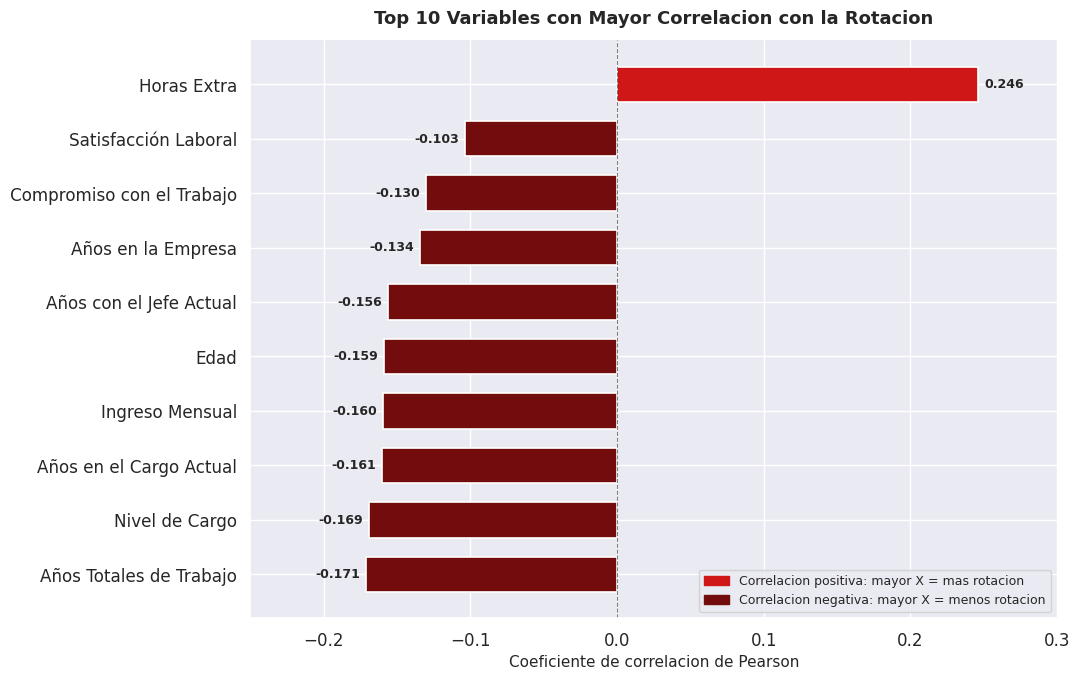


Guardado: fig_11_top10_correlacion_attrition.png

 Top 10 correlaciones con Attrition:
                 Variable  Correlacion (Pearson)
              Horas Extra               0.246118
  Años Totales de Trabajo              -0.171063
           Nivel de Cargo              -0.169105
  Años en el Cargo Actual              -0.160545
          Ingreso Mensual              -0.159840
                     Edad              -0.159205
  Años con el Jefe Actual              -0.156199
       Años en la Empresa              -0.134392
Compromiso con el Trabajo              -0.130016
     Satisfacción Laboral              -0.103481


In [ ]:
# GRÁFICO 6.2 — Top 10 variables con mayor correlación con Rotacion

from matplotlib.patches import Patch

etiquetas = {
    'HorasExtra_num'               : 'Horas Extra',
    'NivelLaboral'                 : 'Nivel de Cargo',
    'IngresoMensual'               : 'Ingreso Mensual',
    'AniosTotalesTrabajo'          : 'Años Totales de Trabajo',
    'Edad'                         : 'Edad',
    'AniosEnEmpresa'               : 'Años en la Empresa',
    'AniosEnRolActual'             : 'Años en el Cargo Actual',
    'AniosConGerenteActual'        : 'Años con el Jefe Actual',
    'InvolucramientoLaboral'       : 'Compromiso con el Trabajo',
    'SatisfaccionLaboral'          : 'Satisfacción Laboral',
    'NumEmpresasTrabajadas'        : 'N Empresas Anteriores',
    'DistanciaCasa'                : 'Distancia al Trabajo',
    'EquilibrioTrabajoVida'        : 'Balance Vida-Trabajo',
    'SatisfaccionAmbiente'         : 'Satisfaccion Ambiente',
    'AniosDesdeUltimaPromocion'    : 'Años sin Promocion',
    'EvaluacionRendimiento'        : 'Desempeño',
    'AumentoPorcentualSalario'     : '% Aumento Salarial',
    'VecesEntrenamientoUltimoAnio' : 'Capacitaciones al Año'}

corr_attr = (matriz_corr['rotacion_num'].drop('rotacion_num').sort_values(key=abs, ascending=False))

top10_df = (corr_attr.head(10).reset_index().rename(columns={'index': 'Variable', 'rotacion_num': 'Correlacion'}))
top10_df['Etiqueta'] = top10_df['Variable'].map(etiquetas).fillna(top10_df['Variable'])
top10_df['Color']    = top10_df['Correlacion'].apply(lambda x: COLOR_ACENTO if x > 0 else COLOR_PRINCIPAL)
top10_df = top10_df.sort_values('Correlacion', ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(top10_df['Etiqueta'], top10_df['Correlacion'], color=top10_df['Color'], edgecolor='white', linewidth=1.2, height=0.65)

for bar, val in zip(bars, top10_df['Correlacion']):
    offset = 0.004 if val > 0 else -0.004
    ha = 'left' if val > 0 else 'right'
    ax.text(val + offset, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', ha=ha, fontsize=9, fontweight='bold')

ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
leyenda = [
    Patch(color=COLOR_ACENTO,    label='Correlacion positiva: mayor X = mas rotacion'),
    Patch(color=COLOR_PRINCIPAL, label='Correlacion negativa: mayor X = menos rotacion')
]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_title('Top 10 Variables con Mayor Correlacion con la Rotacion',fontweight='bold', fontsize=13, pad=12)
ax.set_xlabel('Coeficiente de correlacion de Pearson')
ax.set_xlim(-0.25, 0.30)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('fig_11_top10_correlacion_attrition.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print('Guardado: fig_11_top10_correlacion_attrition.png')

print('\n Top 10 correlaciones con Attrition:')
print(top10_df[['Etiqueta', 'Correlacion']].sort_values('Correlacion', key=abs, ascending=False).head(10).rename(columns={'Etiqueta': 'Variable', 'Correlacion': 'Correlacion (Pearson)'}).to_string(index=False))

**Interpretación — Correlaciones:**

- **Barras naranjas (positivas):** a mayor valor de esa variable, mayor probabilidad de rotación. Ejemplo esperado: `HorasExtra_num`.
- **Barras azules (negativas):** a mayor valor, menor probabilidad de rotación. Ejemplos esperados: `SalarioMensual`, `NivelLaboral`, `Edad`.
- Identificar las **3 variables con mayor correlación absoluta** y destacarlas como los factores de mayor asociación con la rotación.
- Recordar siempre: **correlación ≠ causalidad.**

## Sección 7 — Segmentación por Departamento

Respondemos si los patrones generales se mantienen igual en **Human Resources**, **Research & Development** y **Sales**, o si existen diferencias importantes entre departamentos. Analizamos cuatro dimensiones:

1. Tasa de rotación general
2. Impacto de las horas extra
3. Distribución salarial
4. Niveles de satisfacción

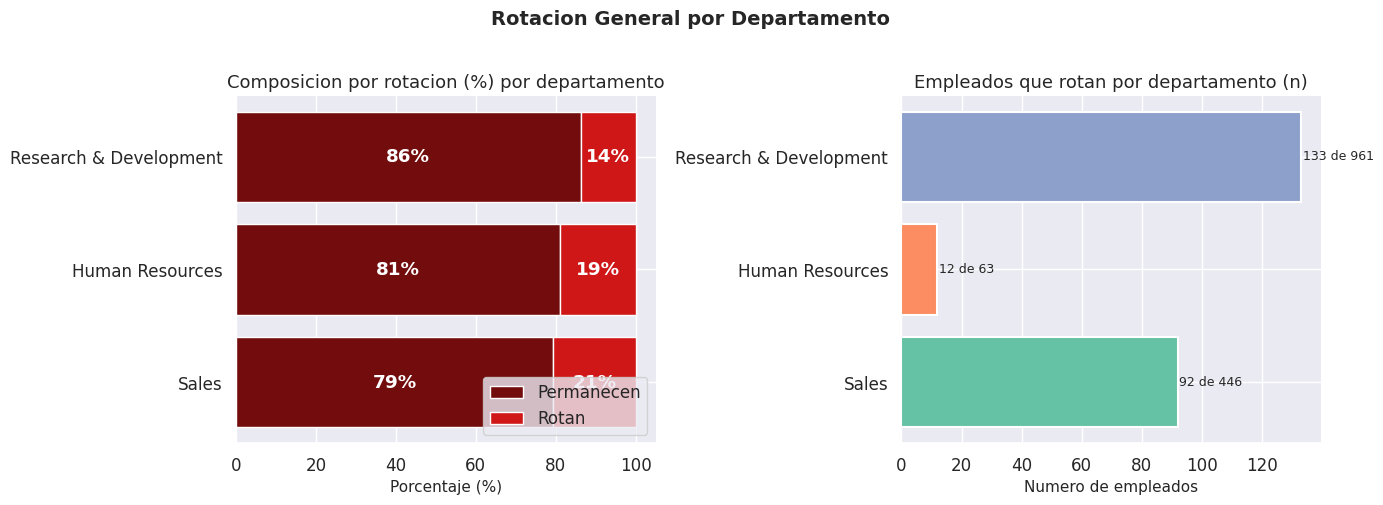


Guardado: fig_12_rotacion_x_dept_general.png

Tabla resumen:
          Departamento  Rotan  Total  Tasa (%)
                 Sales     92    446      20.6
       Human Resources     12     63      19.0
Research & Development    133    961      13.8


In [ ]:
# GRÁFICO 7.1 — Composición de rotación por departamento

tasa_dept = (df_clean.groupby('Departamento')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
tasa_dept['Permanecen'] = tasa_dept['Total'] - tasa_dept['Rotan']
tasa_dept['Tasa (%)']   = (tasa_dept['Rotan'] / tasa_dept['Total'] * 100).round(1)
tasa_dept = tasa_dept.reset_index().sort_values('Tasa (%)', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras apiladas 100%
pct_no  = 100 - tasa_dept['Tasa (%)']
pct_yes = tasa_dept['Tasa (%)']
axes[0].barh(tasa_dept['Departamento'], pct_no,  color=COLOR_PRINCIPAL, label='Permanecen', edgecolor='white')
axes[0].barh(tasa_dept['Departamento'], pct_yes, left=pct_no, color=COLOR_ACENTO, label='Rotan', edgecolor='white')
for i, (no, yes) in enumerate(zip(pct_no, pct_yes)):
    axes[0].text(no/2, i, f'{no:.0f}%',  va='center', ha='center', color='white', fontweight='bold')
    axes[0].text(no+yes/2,i, f'{yes:.0f}%', va='center', ha='center', color='white', fontweight='bold')
axes[0].set_title('Composicion por rotacion (%) por departamento')
axes[0].set_xlabel('Porcentaje (%)')
axes[0].legend(loc='lower right')
sns.despine(ax=axes[0])

# Cantidad absoluta
colores_d = sns.color_palette('Set2', n_colors=len(tasa_dept['Departamento']))
bars = axes[1].barh(tasa_dept['Departamento'], tasa_dept['Rotan'],
                    color=colores_d, edgecolor='white', linewidth=1.5)
for bar, total, rotan in zip(bars, tasa_dept['Total'], tasa_dept['Rotan']):
    axes[1].text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{rotan} de {total}', va='center', fontsize=9)
axes[1].set_title('Empleados que rotan por departamento (n)')
axes[1].set_xlabel('Numero de empleados')
sns.despine(ax=axes[1])

fig.suptitle('Rotacion General por Departamento', fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_12_rotacion_x_dept_general.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print('Guardado: fig_12_rotacion_x_dept_general.png')
print('\nTabla resumen:')
print(tasa_dept[['Departamento', 'Rotan', 'Total', 'Tasa (%)']].to_string(index=False))

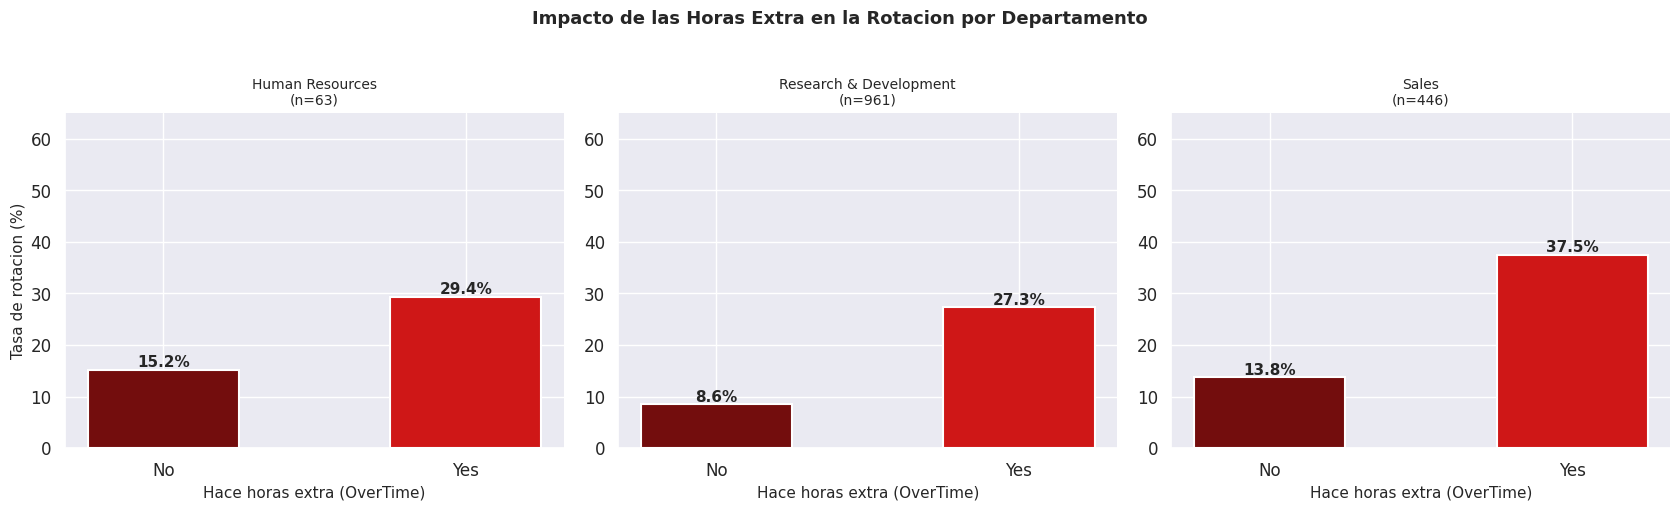


Guardado: fig_13_overtime_x_dept.png


In [ ]:
# GRÁFICO 7.2 — Horas Extra y Rotación dentro de cada Departamento

departamentos = sorted(df_clean['Departamento'].unique())
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, dept in zip(axes, departamentos):
    subset   = df_clean[df_clean['Departamento'] == dept]
    tasa_ot  = (subset.groupby('HorasExtra')['rotacion_num'].agg(['sum', 'count']).rename(columns={'sum': 'Rotan', 'count': 'Total'}))
    tasa_ot['Tasa (%)'] = (tasa_ot['Rotan'] / tasa_ot['Total'] * 100).round(1)
    tasa_ot = tasa_ot.reset_index()

    bars = ax.bar(tasa_ot['HorasExtra'], tasa_ot['Tasa (%)'], color=[COLOR_PRINCIPAL, COLOR_ACENTO], edgecolor='white', linewidth=1.5, width=0.5)
    for bar, val in zip(bars, tasa_ot['Tasa (%)']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val}%', ha='center', fontweight='bold', fontsize=11)

    ax.set_title(f'{dept}\n(n={len(subset)})', fontsize=10)
    ax.set_ylabel('Tasa de rotacion (%)' if ax == axes[0] else '')
    ax.set_xlabel('Hace horas extra (OverTime)')
    ax.set_ylim(0, 65)
    sns.despine(ax=ax)

fig.suptitle('Impacto de las Horas Extra en la Rotacion por Departamento', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_13_overtime_x_dept.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print('Guardado: fig_13_overtime_x_dept.png')

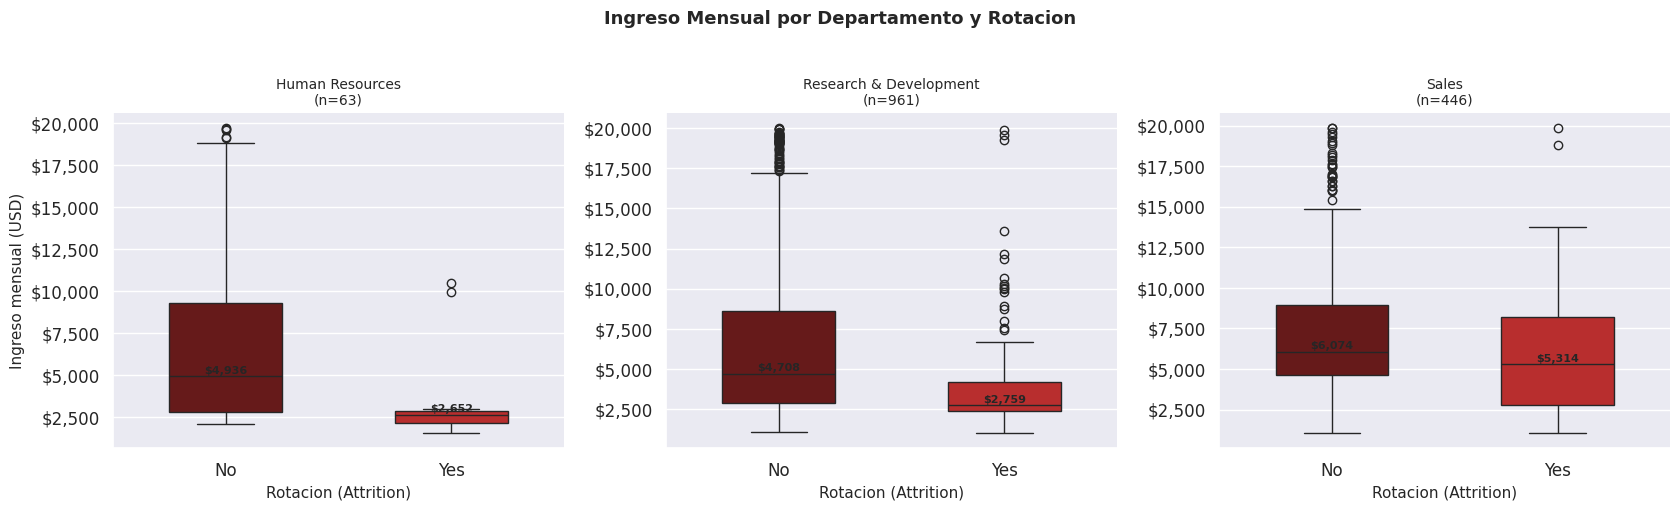

Guardado: fig_14_salario_x_dept.png

 Medianas de ingreso mensual por departamento y rotacion:
Rotacion                Permanecen (mediana $)  Rotan (mediana $)
Departamento                                                     
Human Resources                         4936.0             2652.0
Research & Development                  4708.0             2759.0
Sales                                   6074.0             5314.0


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

departamentos = sorted(df_clean['Departamento'].unique())

# GRÁFICO 7.3 — Ingreso Mensual por Departamento y Rotación

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, dept in zip(axes, departamentos):
    subset = df_clean[df_clean['Departamento'] == dept]
    sns.boxplot(data=subset, x='Rotacion', y='IngresoMensual',
                palette=PALETA_ROTACION, ax=ax, order=['No', 'Yes'], width=0.5)
    for i, grupo in enumerate(['No', 'Yes']):
        med = subset[subset['Rotacion'] == grupo]['IngresoMensual'].median()
        ax.text(i, med + 150, f'${med:,.0f}', ha='center', fontsize=8, fontweight='bold')
    ax.set_title(f'{dept}\n(n={len(subset)})', fontsize=10)
    ax.set_ylabel('Ingreso mensual (USD)' if ax == axes[0] else '')
    ax.set_xlabel('Rotacion (Attrition)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    sns.despine(ax=ax)

fig.suptitle('Ingreso Mensual por Departamento y Rotacion',
             fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_14_salario_x_dept.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig_14_salario_x_dept.png')

print('\n Medianas de ingreso mensual por departamento y rotacion:')
print(df_clean.groupby(['Departamento', 'Rotacion'])['IngresoMensual']
      .median().round(0)
      .unstack()
      .rename(columns={'No': 'Permanecen (mediana $)', 'Yes': 'Rotan (mediana $)'}))

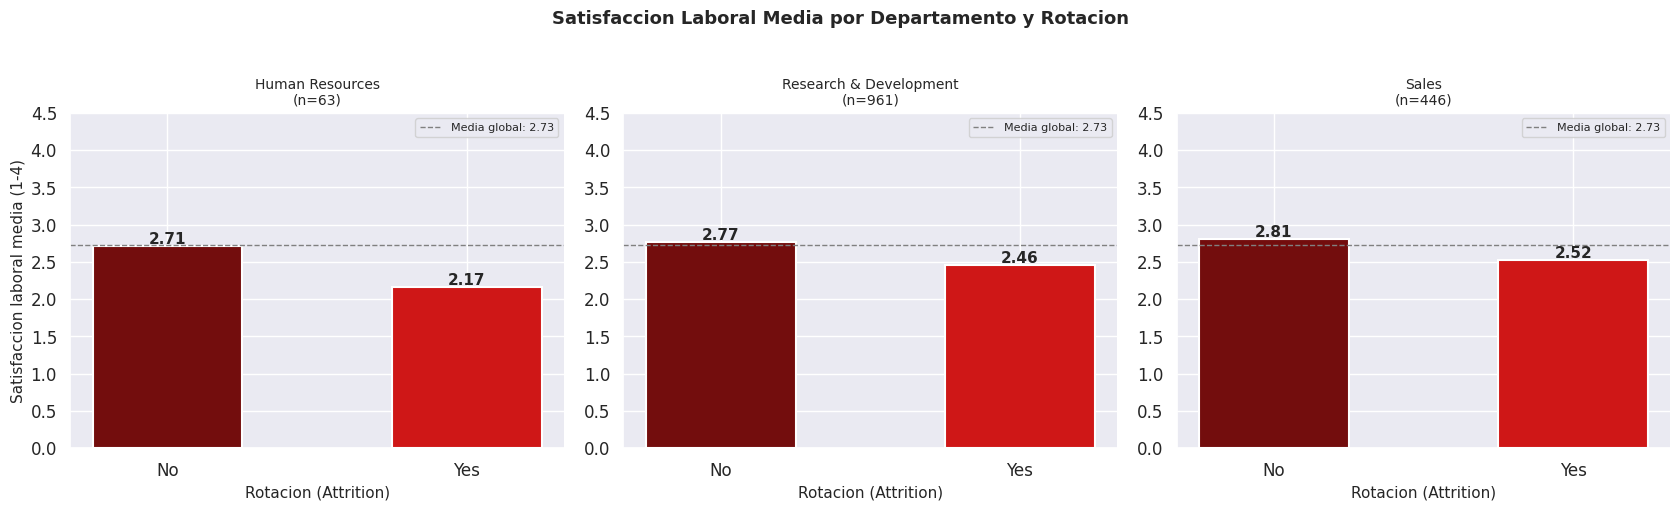

Guardado: fig_15_satisfaccion_x_dept.png

 Satisfaccion laboral media por departamento y rotacion:
Rotacion                Permanecen (media)  Rotan (media)
Departamento                                             
Human Resources                       2.71           2.17
Research & Development                2.77           2.46
Sales                                 2.81           2.52


In [ ]:
# GRÁFICO 7.4 — Satisfacción Laboral por Departamento y Rotación

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, dept in zip(axes, departamentos):
    subset = df_clean[df_clean['Departamento'] == dept]
    media  = subset.groupby('Rotacion')['SatisfaccionLaboral'].mean().round(2).reset_index()
    bars   = ax.bar(media['Rotacion'], media['SatisfaccionLaboral'],
                    color=[PALETA_ROTACION[a] for a in media['Rotacion']],
                    edgecolor='white', linewidth=1.5, width=0.5)
    for bar, val in zip(bars, media['SatisfaccionLaboral']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.03,
                f'{val:.2f}', ha='center', fontweight='bold', fontsize=11)
    media_global = df_clean['SatisfaccionLaboral'].mean()
    ax.axhline(media_global, color='gray', linestyle='--', linewidth=1,
               label=f'Media global: {media_global:.2f}')
    ax.legend(fontsize=8)
    ax.set_title(f'{dept}\n(n={len(subset)})', fontsize=10)
    ax.set_ylabel('Satisfaccion laboral media (1-4)' if ax == axes[0] else '')
    ax.set_xlabel('Rotacion (Attrition)')
    ax.set_ylim(0, 4.5)
    sns.despine(ax=ax)

fig.suptitle('Satisfaccion Laboral Media por Departamento y Rotacion',
             fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_15_satisfaccion_x_dept.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig_15_satisfaccion_x_dept.png')

print('\n Satisfaccion laboral media por departamento y rotacion:')
print(df_clean.groupby(['Departamento', 'Rotacion'])['SatisfaccionLaboral']
      .mean().round(2)
      .unstack()
      .rename(columns={'No': 'Permanecen (media)', 'Yes': 'Rotan (media)'}))

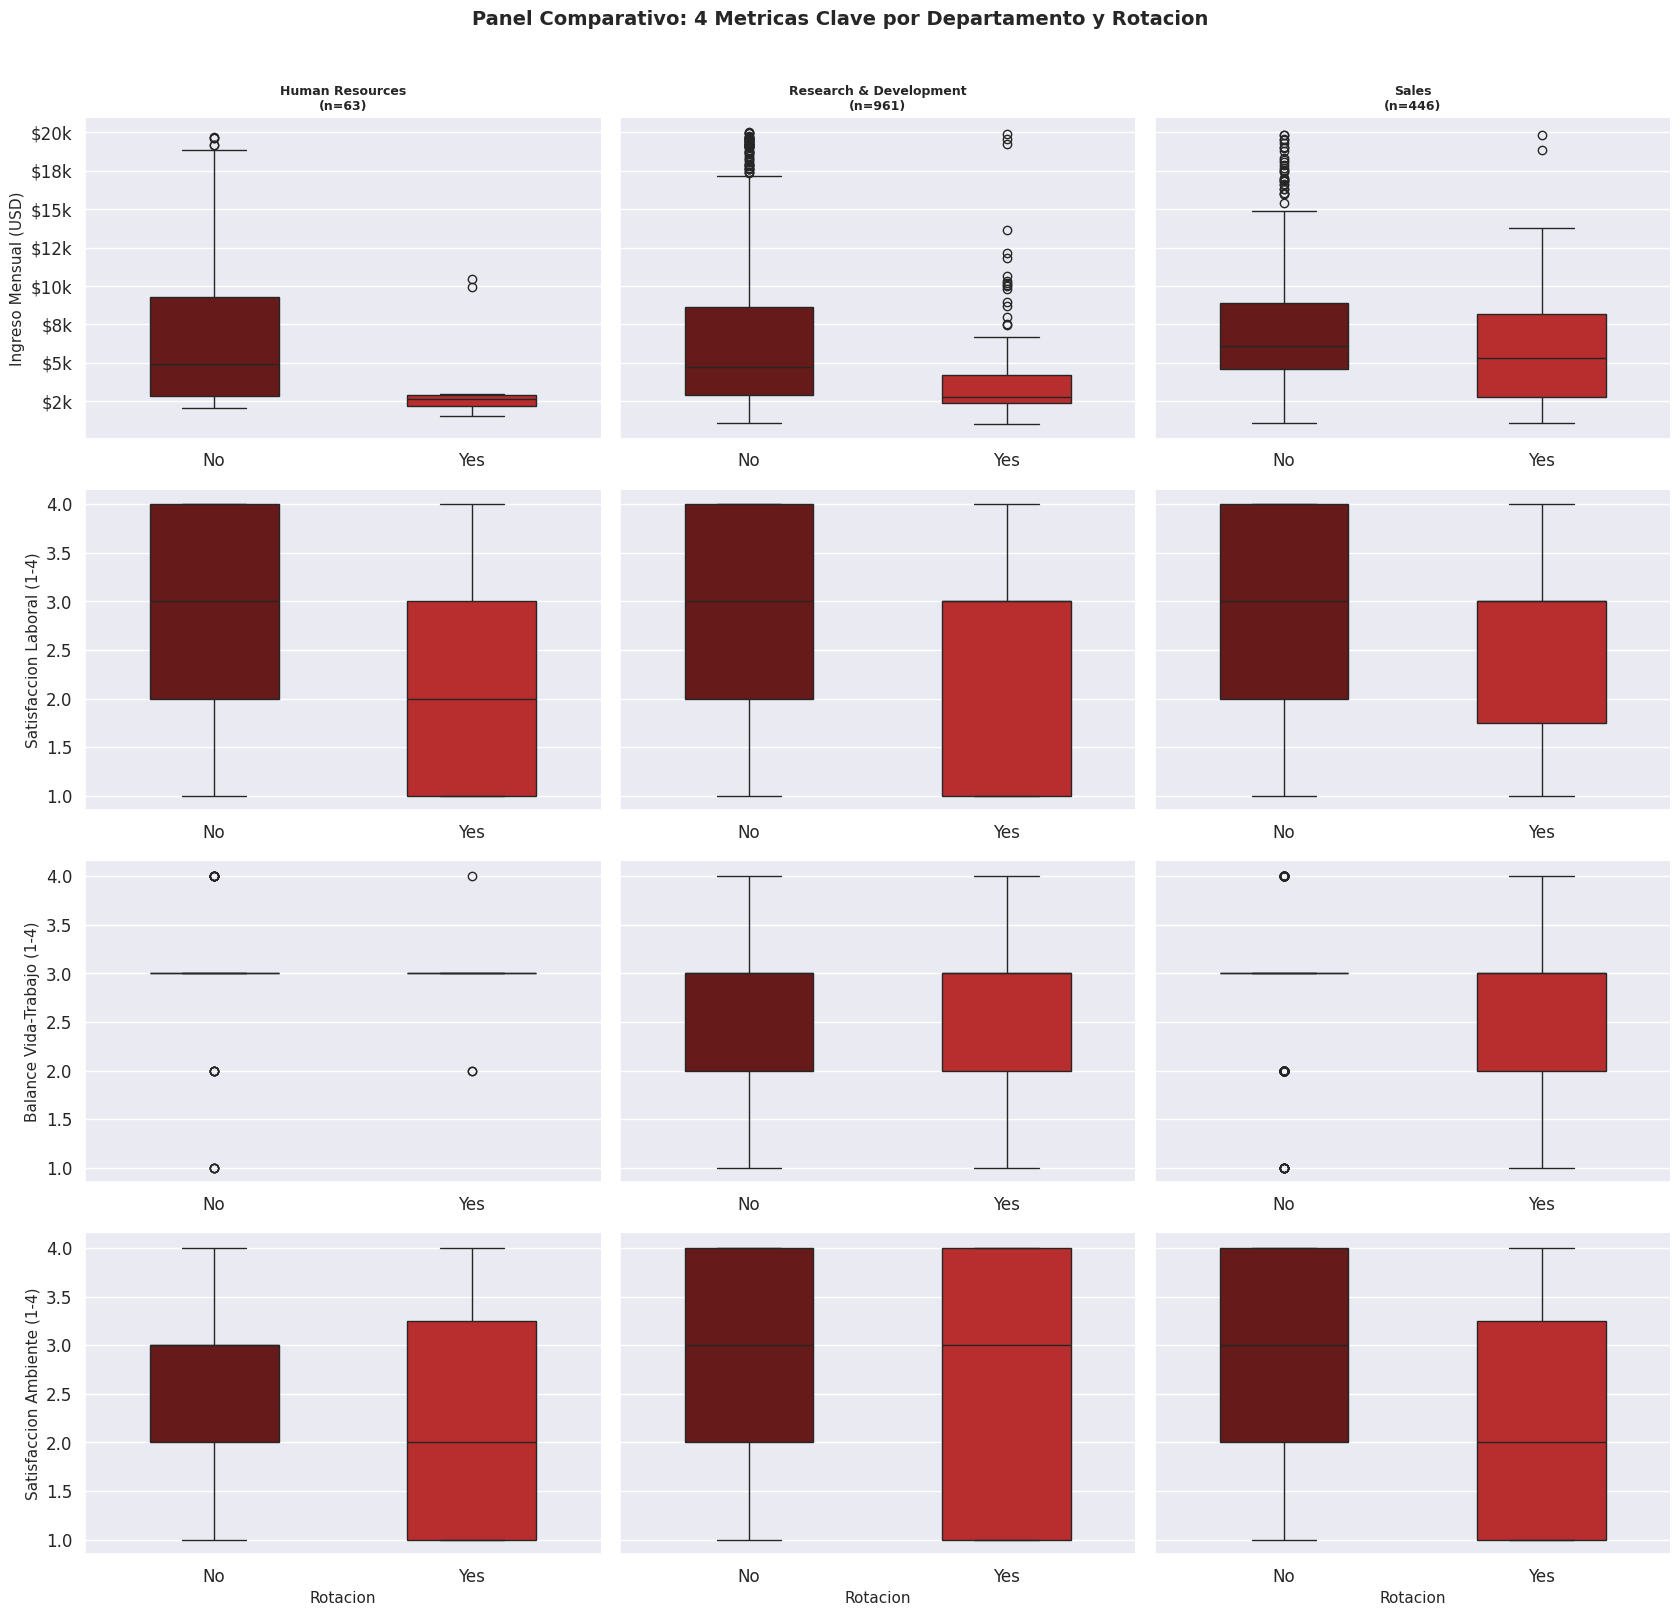

Guardado: fig_16_panel_dept_completo.png


In [ ]:
# GRÁFICO 7.5 — Panel resumen: 4 métricas x 3 departamentos

metricas = {
    'IngresoMensual'           : 'Ingreso Mensual (USD)',
    'SatisfaccionLaboral'         : 'Satisfaccion Laboral (1-4)',
    'EquilibrioTrabajoVida'         : 'Balance Vida-Trabajo (1-4)',
    'SatisfaccionAmbiente' : 'Satisfaccion Ambiente (1-4)'
}

fig, axes = plt.subplots(len(metricas), 3,
                          figsize=(17, 4 * len(metricas)),
                          sharey='row')

for row, (col, titulo) in enumerate(metricas.items()):
    for ax, dept in zip(axes[row], departamentos):
        subset = df_clean[df_clean['Departamento'] == dept]
        sns.boxplot(data=subset, x='Rotacion', y=col,
                    palette=PALETA_ROTACION, ax=ax,
                    order=['No', 'Yes'], width=0.5)
        if row == 0:
            ax.set_title(f'{dept}\n(n={len(subset)})', fontsize=9, fontweight='bold')
        else:
            ax.set_title('')
        ax.set_xlabel('Rotacion' if row == len(metricas) - 1 else '')
        ax.set_ylabel(titulo if ax == axes[row][0] else '')
        if col == 'IngresoMensual':
            ax.yaxis.set_major_formatter(
                mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))
        sns.despine(ax=ax)

fig.suptitle('Panel Comparativo: 4 Metricas Clave por Departamento y Rotacion',
             fontweight='bold', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_16_panel_dept_completo.png', dpi=150, bbox_inches='tight')
plt.show()
print('Guardado: fig_16_panel_dept_completo.png')

In [ ]:
# PRUEBA CHI-CUADRADO

from scipy.stats import chi2_contingency

# Variables categóricas
variables_categoricas_test = [
    'Departamento',
    'EstadoCivil',
    'RolLaboral',
    'Genero'
]

print("RESULTADOS CHI-CUADRADO \n")

for variable in variables_categoricas_test:

    # Tabla de contingencia
    tabla = pd.crosstab(df_clean[variable], df_clean['Rotacion'])

    # Prueba Chi-cuadrado
    chi2, p, dof, expected = chi2_contingency(tabla)

    print(f"Variable: {variable}")
    print(f"Chi2: {chi2:.4f}")
    print(f"P-value: {p:.4f}")

    # Interpretación
    if p < 0.05:
        print("Resultado: Existe relación significativa.\n")
    else:
        print("Resultado: No existe relación significativa.\n")

RESULTADOS CHI-CUADRADO 

Variable: Departamento
Chi2: 10.7960
P-value: 0.0045
Resultado: Existe relación significativa.

Variable: EstadoCivil
Chi2: 46.1637
P-value: 0.0000
Resultado: Existe relación significativa.

Variable: RolLaboral
Chi2: 86.1903
P-value: 0.0000
Resultado: Existe relación significativa.

Variable: Genero
Chi2: 1.1170
P-value: 0.2906
Resultado: No existe relación significativa.



In [ ]:
import pandas as pd

# TABLA RESUMEN FINAL — Una sola tabla para el informe

print('  RESUMEN DE SEGMENTACION POR DEPARTAMENTO')

for dept in sorted(df_clean['Departamento'].unique()):
    s    = df_clean[df_clean['Departamento'] == dept]
    tasa = s['rotacion_num'].mean() * 100
    ot_s = s[s['HorasExtra']=='Yes']['rotacion_num'].mean() * 100
    ot_n = s[s['HorasExtra']=='No']['rotacion_num'].mean()  * 100
    s_r  = s[s['Rotacion']=='Yes']['IngresoMensual'].median()
    s_p  = s[s['Rotacion']=='No']['IngresoMensual'].median()
    j_r  = s[s['Rotacion']=='Yes']['SatisfaccionLaboral'].mean()
    j_p  = s[s['Rotacion']=='No']['SatisfaccionLaboral'].mean()

    print(f'\n {dept} (n={len(s)})')
    print(f'Tasa de rotacion              : {tasa:.1f}%')
    print(f'Rotacion con HorasExtra = Yes   : {ot_s:.1f}%')
    print(f'Rotacion con HorasExtra = No    : {ot_n:.1f}%')
    print(f'     Salario mediano — Rotan       : ${s_r:,.0f}')
    print(f'     Salario mediano — Permanecen  : ${s_p:,.0f}')
    print(f'     Satisfaccion media — Rotan    : {j_r:.2f} / 4')
    print(f'     Satisfaccion media — Perm.    : {j_p:.2f} / 4')

print(' Analisis de correlaciones y segmentacion completado.')

  RESUMEN DE SEGMENTACION POR DEPARTAMENTO

 Human Resources (n=63)
Tasa de rotacion              : 19.0%
Rotacion con HorasExtra = Yes   : 29.4%
Rotacion con HorasExtra = No    : 15.2%
     Salario mediano — Rotan       : $2,652
     Salario mediano — Permanecen  : $4,936
     Satisfaccion media — Rotan    : 2.17 / 4
     Satisfaccion media — Perm.    : 2.71 / 4

 Research & Development (n=961)
Tasa de rotacion              : 13.8%
Rotacion con HorasExtra = Yes   : 27.3%
Rotacion con HorasExtra = No    : 8.6%
     Salario mediano — Rotan       : $2,759
     Salario mediano — Permanecen  : $4,708
     Satisfaccion media — Rotan    : 2.46 / 4
     Satisfaccion media — Perm.    : 2.77 / 4

 Sales (n=446)
Tasa de rotacion              : 20.6%
Rotacion con HorasExtra = Yes   : 37.5%
Rotacion con HorasExtra = No    : 13.8%
     Salario mediano — Rotan       : $5,314
     Salario mediano — Permanecen  : $6,074
     Satisfaccion media — Rotan    : 2.52 / 4
     Satisfaccion media — Perm.    :

---
##Archivos generados en esta sección

| Archivo | Contenido |
|---|---|
| `fig_10_heatmap_correlacion.png` | Matriz de correlacion completa |
| `fig_11_top10_correlacion_attrition.png` | Top 10 variables con mayor asociacion con rotacion |
| `fig_12_rotacion_x_dept_general.png` | Tasa general por departamento |
| `fig_13_overtime_x_dept.png` | Impacto de horas extra por departamento |
| `fig_14_salario_x_dept.png` | Ingreso mensual comparado por departamento |
| `fig_15_satisfaccion_x_dept.png` | Satisfaccion laboral por departamento |
| `fig_16_panel_dept_completo.png` | Panel resumen 4 metricas x 3 departamentos |

> Con esta sección concluye el análisis exploratorio. El siguiente paso es la **Sección 8 — Interpretación y Conclusiones**.

---
# Secciones 8 y 9 — Interpretación, Conclusiones y Modelo Predictivo

| Sección | Contenido |
|---|---|
| **8 — Interpretación y conclusiones** | Respuesta a la pregunta de investigación, hallazgos clave, limitaciones y recomendaciones |
| **9 — Modelo predictivo** | Regresión logística para identificar los factores con mayor peso en la rotación |

In [ ]:
# CONFIGURACIÓN Y CARGA

# Sklearn — modelo predictivo
from sklearn.model_selection    import train_test_split
from sklearn.preprocessing      import StandardScaler, LabelEncoder
from sklearn.linear_model       import LogisticRegression
from sklearn.metrics            import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

---
## Sección 8 — Interpretación y Conclusiones

En esta sección conectamos todos los hallazgos del análisis exploratorio con la pregunta de investigación original, extraemos conclusiones sustentadas en los datos y formulamos recomendaciones concretas.

In [ ]:
import pandas as pd

# 8.1 TABLA DE HALLAZGOS PRINCIPALES
# Genera los números clave para completar la interpretación

print('  HALLAZGOS PRINCIPALES — RESUMEN NUMÉRICO')

#Tasa global
tasa_global = df_clean['rotacion_num'].mean() * 100
print(f'\n Tasa global de rotacion: {tasa_global:.1f}%')

#Por género
for g in df_clean['Genero'].unique():
    t = df_clean[df_clean['Genero']==g]['rotacion_num'].mean()*100
    print(f' Tasa rotacion — {g:<10}       : {t:.1f}%')

# Por estado civil
print()
for c in df_clean['EstadoCivil'].unique():
    t = df_clean[df_clean['EstadoCivil']==c]['rotacion_num'].mean()*100
    print(f' Tasa rotacion — {c:<12}     : {t:.1f}%')

# Por OverTime
print()
for ot in ['Yes', 'No']:
    t = df_clean[df_clean['HorasExtra']==ot]['rotacion_num'].mean()*100
    print(f' Tasa rotacion — OverTime={ot:<3}     : {t:.1f}%')

# Por departamento
print()
for d in sorted(df_clean['Departamento'].unique()):
    t = df_clean[df_clean['Departamento']==d]['rotacion_num'].mean()*100
    print(f'Tasa rotacion — {d:<30}: {t:.1f}%')

# Medianas salariales
print()
for a in ['No', 'Yes']:
    m = df_clean[df_clean['Rotacion']==a]['IngresoMensual'].median()
    print(f'Salario mediano — Attrition={a}    : ${m:,.0f}')

# Satisfacción media
print()
for a in ['No', 'Yes']:
    m = df_clean[df_clean['Rotacion']==a]['SatisfaccionLaboral'].mean()
    print(f'Satisfaccion media — Attrition={a} : {m:.2f} / 4')

#Edad mediana
print()
for a in ['No', 'Yes']:
    m = df_clean[df_clean['Rotacion']==a]['Edad'].median()
    print(f'Edad mediana — Attrition={a}       : {m:.0f} años')


  HALLAZGOS PRINCIPALES — RESUMEN NUMÉRICO

 Tasa global de rotacion: 16.1%
 Tasa rotacion — Female           : 14.8%
 Tasa rotacion — Male             : 17.0%

 Tasa rotacion — Single           : 25.5%
 Tasa rotacion — Married          : 12.5%
 Tasa rotacion — Divorced         : 10.1%

 Tasa rotacion — OverTime=Yes     : 30.5%
 Tasa rotacion — OverTime=No      : 10.4%

Tasa rotacion — Human Resources               : 19.0%
Tasa rotacion — Research & Development        : 13.8%
Tasa rotacion — Sales                         : 20.6%

Salario mediano — Attrition=No    : $5,204
Salario mediano — Attrition=Yes    : $3,202

Satisfaccion media — Attrition=No : 2.78 / 4
Satisfaccion media — Attrition=Yes : 2.47 / 4

Edad mediana — Attrition=No       : 36 años
Edad mediana — Attrition=Yes       : 32 años


### 8.2 Respuesta a la Pregunta de Investigación

> **¿Qué factores demográficos (género, estado civil), laborales (departamento, horas extra, nivel salarial) y de satisfacción (satisfacción laboral, desempeño) se asocian con mayor probabilidad de rotación voluntaria en los empleados de IBM, y cuáles presentan la relación más fuerte según departamento?**

---

**El análisis exploratorio permitió identificar los siguientes hallazgos:**

#### Variables demográficas

- **Género:** los empleados de género masculino presentaron una tasa de rotación del 17.0% frente al 14.8% del femenino. La diferencia no es muy marcada, lo que sugiere que el género no es un factor diferenciador altamente relevante por sí solo.
- **Estado civil:** los empleados solteros registraron la tasa de rotación más alta (25.5%), seguidos por casados (12.5%) y divorciados (10.1%). Esto es consistente con la literatura, que asocia el estado civil soltero con mayor movilidad laboral por menores compromisos familiares.
- **Edad:** los empleados que rotan tienen una edad mediana de 32 años, frente a 36 años de quienes permanecen. Los empleados más jóvenes muestran una mayor tendencia a abandonar la organización.

#### Variables laborales
- **Horas extra (OverTime):** esta fue la variable con mayor diferencia en tasas de rotación. Los empleados que hacen horas extra tienen una tasa del 30.5% frente al 10.4% de quienes no las hacen. Esta brecha sugiere que la carga laboral excesiva es un factor crítico de riesgo de renuncia.
- **Departamento:** el departamento con mayor tasa de rotación fue **Sales** (20.6%), seguido de **Human Resources** (19.0%) y **Research & Development** (13.8%). Esto indica que el contexto departamental influye en la decisión de renuncia, posiblemente por diferencias en cultura, carga de trabajo o estructura salarial.
- **Ingreso mensual:** la mediana salarial de los empleados que rotan fue de $3,202 frente a $5,204 de quienes permanecen, una diferencia de $2,002. Esto confirma que el nivel salarial es uno de los factores más asociados con la retención.

#### Variables de satisfacción
- **Satisfacción laboral:** los empleados que rotan reportaron en promedio una satisfacción de 2.47/4, frente a 2.78/4 de quienes permanecen. Se confirma una relación inversa esperada, donde menor satisfacción se asocia con mayor rotación.
- **Balance vida-trabajo y satisfacción con el ambiente:** la satisfacción media con el ambiente laboral es de 2.46/4 para quienes rotan, versus 2.77/4 para quienes permanecen. Similarmente, el equilibrio vida-trabajo es de 2.66/4 para quienes rotan y 2.78/4 para quienes permanecen. En ambos casos, los empleados que rotan reportan niveles de satisfacción ligeramente inferiores.

#### Factores con mayor correlación

Según el análisis de correlaciones de Pearson, las tres variables con mayor asociación con la rotación fueron:
1. **Horas Extra (`HorasExtra_num`)** (r = 0.246): Los empleados que realizan horas extra tienen una mayor probabilidad de rotar.
2. **Años Totales Trabajados (`AniosTotalesTrabajo`)** (r = -0.171): A mayor cantidad de años trabajados, menor es la probabilidad de rotación.
3. **Nivel Laboral (`NivelLaboral`)** (r = -0.169): Empleados con niveles laborales más altos tienden a tener menor probabilidad de rotación.

### 8.3 Limitaciones del Análisis

Todo análisis tiene límites que deben reconocerse para una interpretación honesta de los resultados:

| # | Limitación | Implicación |
|---|---|---|
| 1 | El dataset no distingue rotación voluntaria (renuncia) de involuntaria (despido) | La variable `Attrition=Yes` podría incluir casos de despido, lo que sesgaría el perfil del "empleado que se va" |
| 2 | Los datos son un snapshot histórico sin fecha específica | No podemos establecer tendencias temporales ni saber si el contexto organizacional ha cambiado |
| 3 | Las correlaciones de Pearson miden asociación lineal | Pueden existir relaciones no lineales entre variables que este método no captura |
| 4 | El dataset está desbalanceado (~16% rotación vs ~84% retención) | Los modelos y estadísticos pueden estar sesgados hacia la clase mayoritaria |
| 5 | El análisis es descriptivo, no causal | No podemos afirmar que ninguna variable *cause* la rotación, solo que se asocia con ella |

### 8.4 Recomendaciones

Con base en los hallazgos del análisis, se proponen las siguientes recomendaciones para el área de Recursos Humanos:

| Prioridad | Recomendación | Basada en |
|---|---|---|
| 🔴 Alta | Revisar y regular las políticas de horas extra, especialmente en los departamentos con mayor tasa de rotación | Alto impacto de `OverTime` en la rotación |
| 🔴 Alta | Implementar revisiones salariales focalizadas en empleados con menor ingreso y mayor antigüedad | Brecha salarial entre quienes rotan y quienes permanecen |
| 🟡 Media | Diseñar programas de retención temprana para empleados con menos de 3 años en la empresa | Mayor concentración de rotación en empleados recientes |
| 🟡 Media | Aplicar encuestas de satisfacción periódicas diferenciadas por departamento | Diferencias en satisfacción laboral entre departamentos |
| 🟢 Preventiva | Prestar especial atención al perfil de empleados solteros con horas extra y bajo salario | Combinación de factores de riesgo más frecuente en quienes rotan |

> **Nota:** estas recomendaciones son orientativas y deben complementarse con análisis cualitativos (entrevistas de salida, encuestas de clima) para diseñar intervenciones específicas.

---
# Sección 9 — Modelo Predictivo

En esta sección construimos y comparamos modelos de clasificación para predecir la probabilidad de rotación voluntaria de un empleado. El proceso sigue cuatro pasos:

| Paso | Descripción |
|---|---|
| **9.1** | Preparación de datos y codificación de variables |
| **9.2** | Análisis de Componentes Principales (PCA) |
| **9.3** | División entrenamiento / prueba y estandarización |
| **9.4** | Entrenamiento de 3 modelos: Regresión Logística, Árbol de Decisión, Random Forest |
| **9.5** | Evaluación y comparación de modelos |
| **9.6** | Interpretación de coeficientes — factores más influyentes |
| **9.7** | Resumen ejecutivo |

> 📚 **¿Por qué Regresión Logística?**  
> Estima la *probabilidad* de que ocurra un evento binario (rotar = 1, permanecer = 0) a partir de múltiples variables. Su resultado siempre está entre 0 y 1, y sus coeficientes son directamente interpretables como el peso de cada factor.
>
> 📚 **¿Por qué también Árbol y Random Forest?**  
> Permiten capturar relaciones no lineales entre variables y sirven de comparación para validar que los hallazgos de la regresión logística son robustos.

## 9.1 Preparación de Datos para el Modelo

Los algoritmos de Machine Learning solo trabajan con números. Por eso debemos:
1. **Codificar** las variables categóricas (texto → número) usando `LabelEncoder`
2. **Guardar los encoders** en un diccionario para poder usarlos luego en predicciones nuevas
3. **Separar** las variables predictoras (`X`) de la variable objetivo (`y`)

> ⚠️ **Importante:** guardamos cada `LabelEncoder` en `encoders_dict` porque cuando hagamos una predicción nueva necesitaremos transformar los datos del mismo modo que durante el entrenamiento.

In [ ]:
# 9.1 PREPARACIÓN DE DATOS

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# -- Copia de trabajo
df_modelo = df_clean.copy()

# -- Variables categóricas a codificar
vars_cat_encode = [
    'Genero', 'EstadoCivil', 'Departamento',
    'RolLaboral', 'ViajeNegocios', 'CampoEducacion'
]

# Guardamos cada encoder para reutilizarlo en predicciones nuevas
encoders_dict = {}

for col in vars_cat_encode:
    if col in df_modelo.columns:
        le = LabelEncoder()
        df_modelo[col + '_enc'] = le.fit_transform(df_modelo[col])
        encoders_dict[col] = le  # guardamos el encoder entrenado

print('Encoders guardados para:')
for col, enc in encoders_dict.items():
    print(f'  {col:<20} → categorías: {list(enc.classes_)}')

# -- Variables predictoras
features = [
    # Demográficas
    'Edad', 'Genero_enc', 'EstadoCivil_enc',
    # Laborales
    'Departamento_enc', 'RolLaboral_enc', 'NivelLaboral',
    'HorasExtra_num', 'ViajeNegocios_enc',
    'IngresoMensual', 'AumentoPorcentualSalario',
    'AniosEnEmpresa', 'AniosEnRolActual',
    'AniosDesdeUltimaPromocion', 'AniosConGerenteActual',
    'AniosTotalesTrabajo', 'NumEmpresasTrabajadas',
    'DistanciaCasa', 'VecesEntrenamientoUltimoAnio',
    # Satisfacción
    'SatisfaccionLaboral', 'SatisfaccionAmbiente',
    'EquilibrioTrabajoVida', 'InvolucramientoLaboral', 'EvaluacionRendimiento'
]

# Filtrar solo las que existen en el dataset
features = [f for f in features if f in df_modelo.columns]

X = df_modelo[features]
y = df_modelo['rotacion_num']

print(f'\n✅ Variables predictoras: {len(features)}')
print(f'   Permanecen (0): {(y==0).sum()} | Rotan (1): {(y==1).sum()}')
print(f'   Tasa de rotación en el dataset: {y.mean()*100:.1f}%')

Encoders guardados para:
  Genero               → categorías: ['Female', 'Male']
  EstadoCivil          → categorías: ['Divorced', 'Married', 'Single']
  Departamento         → categorías: ['Human Resources', 'Research & Development', 'Sales']
  RolLaboral           → categorías: ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
  ViajeNegocios        → categorías: ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
  CampoEducacion       → categorías: ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']

✅ Variables predictoras: 23
   Permanecen (0): 1233 | Rotan (1): 237
   Tasa de rotación en el dataset: 16.1%


## 9.2 Análisis de Componentes Principales (PCA)

El PCA reduce la dimensionalidad del dataset y nos permite entender qué variables concentran más información. Lo aplicamos **antes** de entrenar el modelo para:
- Verificar si hay redundancia entre variables
- Identificar qué variables son estructuralmente más importantes

> **Nota:** el PCA se aplica sobre `X` estandarizado solo para análisis visual. El modelo predictivo usará las variables originales (no transformadas por PCA) porque la regresión logística es más interpretable con las variables en su forma original.

In [ ]:
# 9.2 PCA — ANÁLISIS DE COMPONENTES PRINCIPALES

from sklearn.decomposition import PCA

# Estandarizar para PCA (sensible a escala)
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X)

# Ajustar PCA con todas las componentes
pca = PCA()
pca.fit(X_pca_scaled)

varianza_explicada  = pca.explained_variance_ratio_
varianza_acumulada  = varianza_explicada.cumsum()

# Componentes necesarias para explicar el 80% y 90%
comp_80 = next(i+1 for i, v in enumerate(varianza_acumulada) if v >= 0.80)
comp_90 = next(i+1 for i, v in enumerate(varianza_acumulada) if v >= 0.90)

print('Varianza explicada por componente (primeros 10):')
for i, v in enumerate(varianza_explicada[:10]):
    print(f'  Componente {i+1:>2}: {v:.4f} ({v*100:.1f}%)')
print(f'\n  Componentes necesarias para explicar el 80%: {comp_80}')
print(f'  Componentes necesarias para explicar el 90%: {comp_90}')
print(f'  Total de variables originales              : {X.shape[1]}')

Varianza explicada por componente (primeros 10):
  Componente  1: 0.2026 (20.3%)
  Componente  2: 0.0804 (8.0%)
  Componente  3: 0.0779 (7.8%)
  Componente  4: 0.0702 (7.0%)
  Componente  5: 0.0495 (5.0%)
  Componente  6: 0.0472 (4.7%)
  Componente  7: 0.0466 (4.7%)
  Componente  8: 0.0451 (4.5%)
  Componente  9: 0.0438 (4.4%)
  Componente 10: 0.0423 (4.2%)

  Componentes necesarias para explicar el 80%: 13
  Componentes necesarias para explicar el 90%: 15
  Total de variables originales              : 23


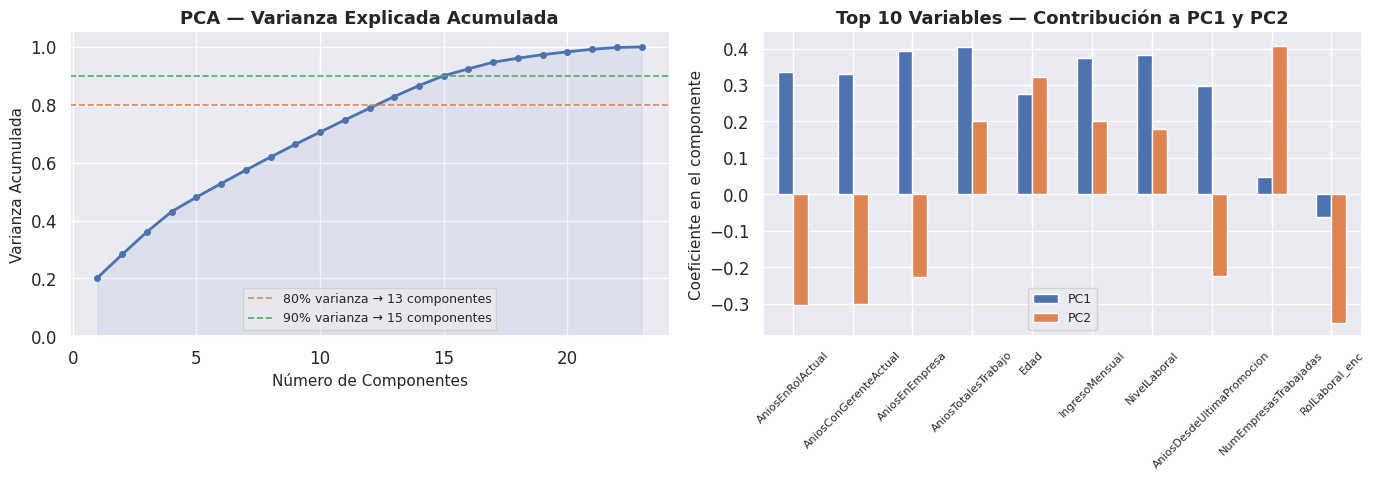

💾 Guardado: fig_pca_analisis.png


In [ ]:
# ============================================================
# GRÁFICO — Varianza acumulada explicada por PCA
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Varianza acumulada
axes[0].plot(range(1, len(varianza_acumulada)+1), varianza_acumulada,
             marker='o', color='#4C72B0', linewidth=2, markersize=4)
axes[0].axhline(0.80, color='#DD8452', linestyle='--', linewidth=1.2,
                label=f'80% varianza → {comp_80} componentes')
axes[0].axhline(0.90, color='#55A868', linestyle='--', linewidth=1.2,
                label=f'90% varianza → {comp_90} componentes')
axes[0].fill_between(range(1, len(varianza_acumulada)+1),
                     varianza_acumulada, alpha=0.08, color='#4C72B0')
axes[0].set_xlabel('Número de Componentes')
axes[0].set_ylabel('Varianza Acumulada')
axes[0].set_title('PCA — Varianza Explicada Acumulada', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_ylim(0, 1.05)
sns.despine(ax=axes[0])

# Subplot 2: Contribución de variables a PC1 y PC2
componentes_df = pd.DataFrame(
    pca.components_[:2],
    columns=features,
    index=['PC1', 'PC2']
)
top_contrib = componentes_df.abs().sum().sort_values(ascending=False).head(10).index
contrib_plot = componentes_df[top_contrib].T

contrib_plot.plot(kind='bar', ax=axes[1],
                  color=['#4C72B0', '#DD8452'], edgecolor='white')
axes[1].set_title('Top 10 Variables — Contribución a PC1 y PC2', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Coeficiente en el componente')
axes[1].tick_params(axis='x', rotation=45, labelsize=8)
axes[1].legend(fontsize=9)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.savefig('fig_pca_analisis.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Guardado: fig_pca_analisis.png')

## 9.3 División Entrenamiento / Prueba y Estandarización

Dividimos el dataset en dos partes:
- **80% entrenamiento:** el modelo aprende patrones con estos datos
- **20% prueba:** evaluamos qué tan bien generaliza a datos que nunca vio

Usamos `stratify=y` para garantizar que la proporción de rotación (16%/84%) se mantenga igual en ambos conjuntos.

**Estandarización:** la Regresión Logística requiere que todas las variables estén en la misma escala (media=0, std=1). El `scaler_modelo` se entrena **solo** con los datos de entrenamiento y se aplica a los de prueba — esto evita **data leakage** (filtración de información del futuro hacia el entrenamiento).

In [ ]:
# ============================================================
# 9.3 DIVISIÓN Y ESTANDARIZACIÓN
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y       # mantiene la proporción de clases
)

# Estandarización — IMPORTANTE: fit solo en train, transform en ambos
scaler_modelo = StandardScaler()
X_train_sc    = scaler_modelo.fit_transform(X_train)   # aprende media y std
X_test_sc     = scaler_modelo.transform(X_test)        # aplica sin aprender

print('✅ División del dataset:')
print(f'   Entrenamiento : {X_train.shape[0]:>4} registros  '
      f'| Rotación: {y_train.mean()*100:.1f}%')
print(f'   Prueba        : {X_test.shape[0]:>4} registros  '
      f'| Rotación: {y_test.mean()*100:.1f}%')
print(f'\n✅ Estandarización aplicada con scaler_modelo')
print(f'   Media de X_train_sc ≈ {X_train_sc.mean():.4f}  (debe ser ≈ 0)')
print(f'   Std  de X_train_sc ≈ {X_train_sc.std():.4f}  (debe ser ≈ 1)')

✅ División del dataset:
   Entrenamiento : 1176 registros  | Rotación: 16.2%
   Prueba        :  294 registros  | Rotación: 16.0%

✅ Estandarización aplicada con scaler_modelo
   Media de X_train_sc ≈ -0.0000  (debe ser ≈ 0)
   Std  de X_train_sc ≈ 1.0000  (debe ser ≈ 1)


## 9.4 Entrenamiento de Modelos

Entrenamos tres modelos con distintos enfoques para comparar su rendimiento:

| Modelo | Ventaja principal | Requiere estandarización |
|---|---|---|
| **Regresión Logística** | Coeficientes interpretables | ✅ Sí |
| **Árbol de Decisión** | Visualizable, reglas claras | ❌ No |
| **Random Forest** | Alta precisión, robusto | ❌ No |

> En los tres usamos `class_weight='balanced'` para compensar el desbalance del dataset (solo ~16% de casos de rotación).

In [ ]:
# ============================================================
# 9.4 ENTRENAMIENTO DE LOS TRES MODELOS
# ============================================================
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ── MODELO 1: Regresión Logística ──────────────────────────
# Usa datos estandarizados (X_train_sc)
modelo_lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
modelo_lr.fit(X_train_sc, y_train)
print(f'✅ Regresión Logística entrenada  '
      f'| Iteraciones: {modelo_lr.n_iter_[0]}')

# ── MODELO 2: Árbol de Decisión ────────────────────────────
# No requiere estandarización (usa X_train directamente)
modelo_tree = DecisionTreeClassifier(
    max_depth=5,           # limita profundidad para evitar sobreajuste
    min_samples_split=10,  # mínimo de muestras para dividir un nodo
    min_samples_leaf=5,    # mínimo de muestras en una hoja
    class_weight='balanced',
    random_state=42
)
modelo_tree.fit(X_train, y_train)
print('✅ Árbol de Decisión entrenado')

# ── MODELO 3: Random Forest ────────────────────────────────
# Ensemble de 300 árboles — más robusto que un árbol individual
modelo_rf = RandomForestClassifier(
    n_estimators=300,      # número de árboles
    max_depth=10,          # profundidad máxima de cada árbol
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1              # usa todos los núcleos disponibles
)
modelo_rf.fit(X_train, y_train)
print('✅ Random Forest entrenado')

✅ Regresión Logística entrenada  | Iteraciones: 22
✅ Árbol de Decisión entrenado
✅ Random Forest entrenado


## 9.5 Evaluación y Comparación de Modelos

Evaluamos los tres modelos con las mismas métricas para elegir el más adecuado:

- **Accuracy:** porcentaje de predicciones correctas totales
- **Precision:** de los que predijo como "rota", ¿cuántos realmente rotaron?
- **Recall:** de los que realmente rotaron, ¿cuántos detectó correctamente? *(métrica más importante en este contexto)*
- **F1-Score:** promedio armónico entre Precision y Recall
- **AUC-ROC:** capacidad global del modelo para distinguir entre las dos clases

> 💡 En un problema de rotación, el **Recall** es la métrica más crítica: queremos detectar la mayor cantidad posible de empleados en riesgo, aunque eso implique algunas falsas alarmas.

In [ ]:
# ============================================================
# 9.5 EVALUACIÓN Y COMPARACIÓN DE MODELOS
# ============================================================

def evaluar_modelo(nombre, modelo, X_eval, y_eval, estandarizado=True):
    """
    Evalúa un modelo y retorna un diccionario con todas sus métricas.
    Si estandarizado=True, X_eval ya viene transformado por scaler_modelo.
    Si estandarizado=False, se usa X_eval sin transformar.
    """
    y_pred = modelo.predict(X_eval)
    y_prob = modelo.predict_proba(X_eval)[:, 1]

    return {
        'Modelo'    : nombre,
        'Accuracy'  : round(accuracy_score(y_eval, y_pred), 4),
        'Precision' : round(precision_score(y_eval, y_pred), 4),
        'Recall'    : round(recall_score(y_eval, y_pred), 4),
        'F1-Score'  : round(f1_score(y_eval, y_pred), 4),
        'AUC-ROC'   : round(roc_auc_score(y_eval, y_prob), 4),
        '_y_pred'   : y_pred,
        '_y_prob'   : y_prob
    }

# Evaluar los tres modelos
res_lr   = evaluar_modelo('Regresión Logística', modelo_lr,   X_test_sc, y_test)
res_tree = evaluar_modelo('Árbol de Decisión',   modelo_tree, X_test,    y_test)
res_rf   = evaluar_modelo('Random Forest',       modelo_rf,   X_test,    y_test)

# Tabla comparativa
cols_metricas = ['Modelo', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
df_resultados = pd.DataFrame([res_lr, res_tree, res_rf])[cols_metricas]

print('='*65)
print('  COMPARACIÓN DE MODELOS — DATOS DE PRUEBA')
print('='*65)
print(df_resultados.to_string(index=False))
print('='*65)

# Mejor modelo según Recall (más importante para este problema)
mejor = df_resultados.loc[df_resultados['Recall'].idxmax(), 'Modelo']
print(f'\n  Mejor modelo por Recall: {mejor}')

  COMPARACIÓN DE MODELOS — DATOS DE PRUEBA
             Modelo  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Regresión Logística    0.7449     0.3542  0.7234    0.4755   0.8266
  Árbol de Decisión    0.6871     0.2816  0.6170    0.3867   0.6643
      Random Forest    0.8163     0.3600  0.1915    0.2500   0.7819

  Mejor modelo por Recall: Regresión Logística


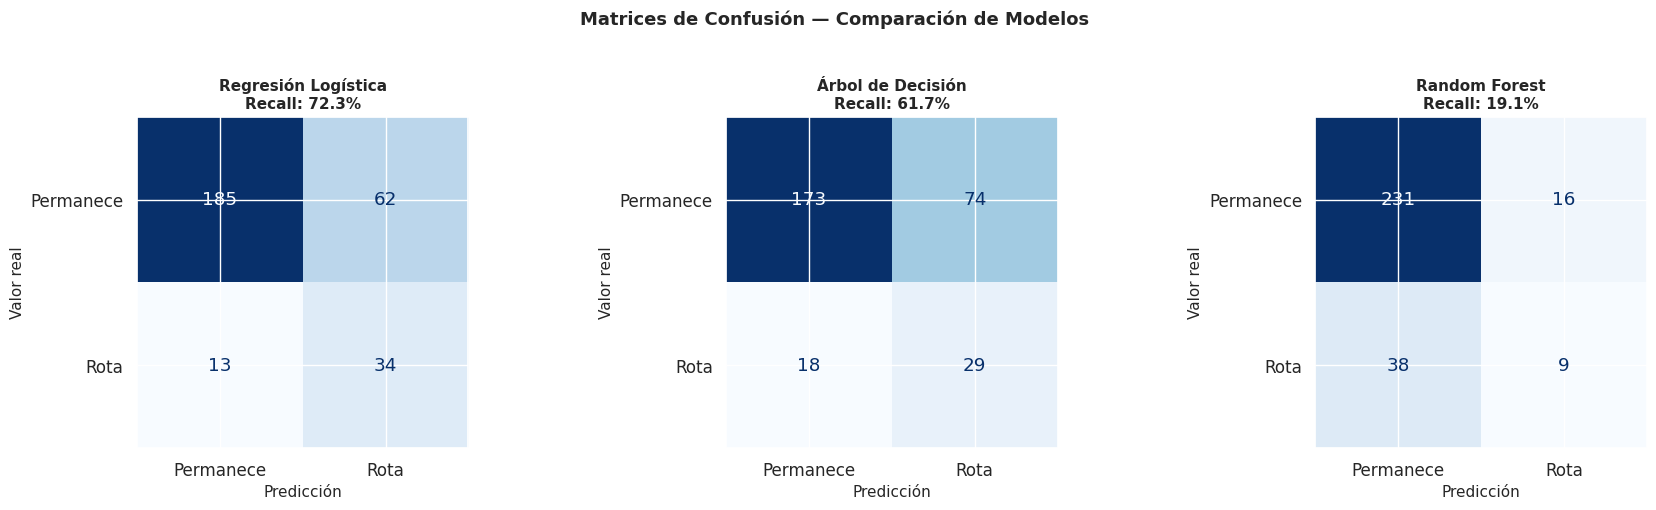

💾 Guardado: fig_matrices_confusion.png


In [ ]:
# ============================================================
# GRÁFICO — Matrices de confusión de los tres modelos
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

modelos_info = [
    ('Regresión Logística', res_lr['_y_pred']),
    ('Árbol de Decisión',   res_tree['_y_pred']),
    ('Random Forest',       res_rf['_y_pred'])
]

for ax, (nombre, y_pred_m) in zip(axes, modelos_info):
    cm = confusion_matrix(y_test, y_pred_m)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Permanece', 'Rota']
    ).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')

    tn, fp, fn, tp = cm.ravel()
    recall_m = tp / (tp + fn) if (tp + fn) > 0 else 0
    ax.set_title(f'{nombre}\nRecall: {recall_m:.1%}',
                 fontweight='bold', fontsize=11)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Valor real')

fig.suptitle('Matrices de Confusión — Comparación de Modelos',
             fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_matrices_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Guardado: fig_matrices_confusion.png')

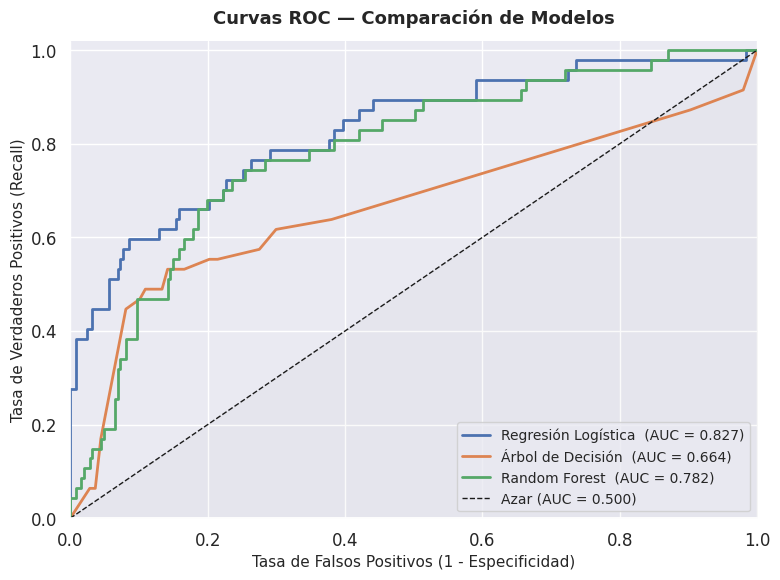

💾 Guardado: fig_curvas_roc.png


In [ ]:
# ============================================================
# GRÁFICO — Curvas ROC de los tres modelos
# ============================================================
fig, ax = plt.subplots(figsize=(8, 6))

colores_roc = ['#4C72B0', '#DD8452', '#55A868']
datos_roc = [
    ('Regresión Logística', res_lr['_y_prob'],   res_lr['AUC-ROC']),
    ('Árbol de Decisión',   res_tree['_y_prob'],  res_tree['AUC-ROC']),
    ('Random Forest',       res_rf['_y_prob'],    res_rf['AUC-ROC'])
]

for (nombre, y_prob_m, auc_m), color in zip(datos_roc, colores_roc):
    fpr_m, tpr_m, _ = roc_curve(y_test, y_prob_m)
    ax.plot(fpr_m, tpr_m, color=color, linewidth=2,
            label=f'{nombre}  (AUC = {auc_m:.3f})')

ax.plot([0,1], [0,1], 'k--', linewidth=1, label='Azar (AUC = 0.500)')
ax.fill_between([0,1], [0,1], alpha=0.04, color='gray')

ax.set_title('Curvas ROC — Comparación de Modelos',
             fontweight='bold', fontsize=13, pad=12)
ax.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (Recall)')
ax.legend(fontsize=10, loc='lower right')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('fig_curvas_roc.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Guardado: fig_curvas_roc.png')

## 9.6 Interpretación de Coeficientes — Regresión Logística

Los coeficientes de la regresión logística indican el **peso estandarizado** de cada variable sobre la probabilidad de rotación:

- **Coeficiente positivo (🟠):** a mayor valor de esa variable, mayor probabilidad de rotar
- **Coeficiente negativo (🔵):** a mayor valor de esa variable, menor probabilidad de rotar

> Este gráfico responde directamente la pregunta de investigación: *¿cuáles factores tienen la relación más fuerte con la rotación?*

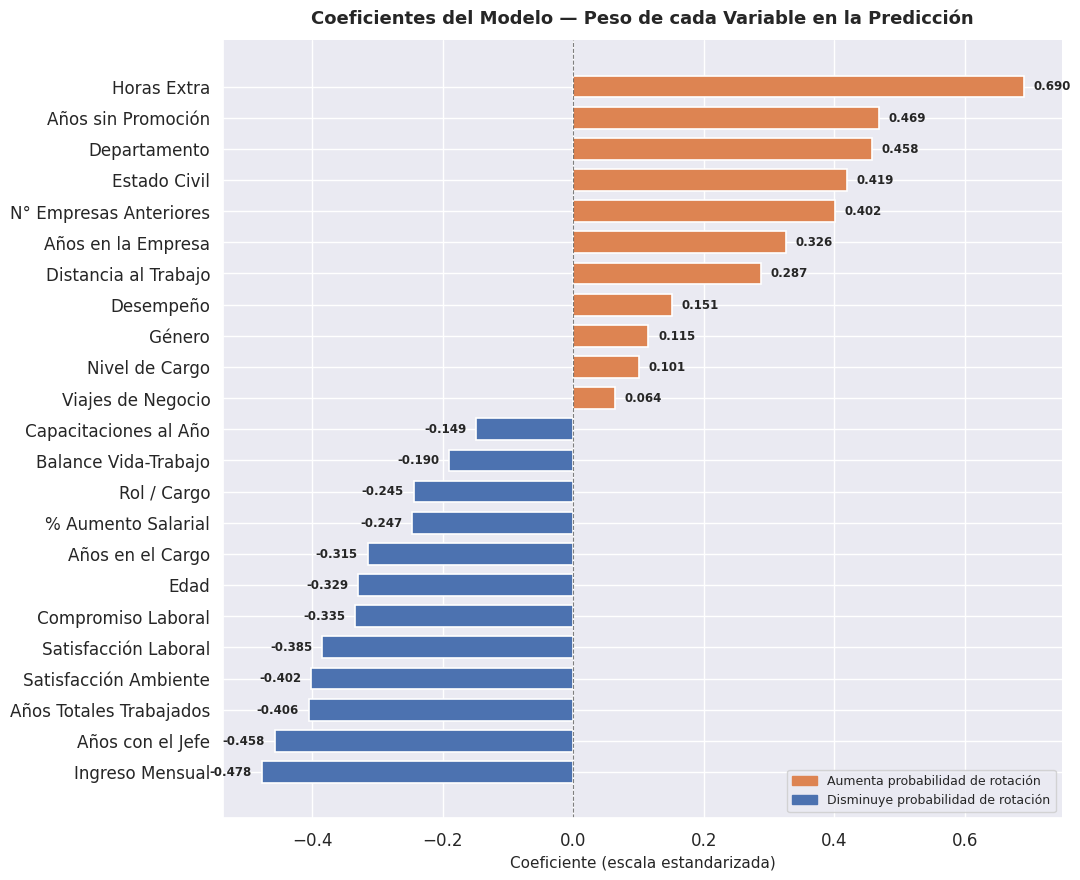

💾 Guardado: fig_coeficientes_modelo.png

Top 5 factores de MAYOR RIESGO (coeficiente positivo):
              Etiqueta  Coeficiente
           Horas Extra     0.690479
    Años sin Promoción     0.468789
          Departamento     0.457653
          Estado Civil     0.419343
N° Empresas Anteriores     0.401553

Top 5 factores PROTECTORES (coeficiente negativo):
               Etiqueta  Coeficiente
        Ingreso Mensual    -0.477723
       Años con el Jefe    -0.457802
Años Totales Trabajados    -0.405741
  Satisfacción Ambiente    -0.402188
   Satisfacción Laboral    -0.384575


In [ ]:
# ============================================================
# 9.6 COEFICIENTES DE LA REGRESIÓN LOGÍSTICA
# ============================================================
from matplotlib.patches import Patch

etiquetas_modelo = {
    'Edad'                       : 'Edad',
    'Genero_enc'                 : 'Género',
    'EstadoCivil_enc'            : 'Estado Civil',
    'Departamento_enc'           : 'Departamento',
    'RolLaboral_enc'             : 'Rol / Cargo',
    'NivelLaboral'               : 'Nivel de Cargo',
    'HorasExtra_num'             : 'Horas Extra',
    'ViajeNegocios_enc'          : 'Viajes de Negocio',
    'IngresoMensual'             : 'Ingreso Mensual',
    'AumentoPorcentualSalario'   : '% Aumento Salarial',
    'AniosEnEmpresa'             : 'Años en la Empresa',
    'AniosEnRolActual'           : 'Años en el Cargo',
    'AniosDesdeUltimaPromocion'  : 'Años sin Promoción',
    'AniosConGerenteActual'      : 'Años con el Jefe',
    'AniosTotalesTrabajo'        : 'Años Totales Trabajados',
    'NumEmpresasTrabajadas'      : 'N° Empresas Anteriores',
    'DistanciaCasa'              : 'Distancia al Trabajo',
    'VecesEntrenamientoUltimoAnio': 'Capacitaciones al Año',
    'SatisfaccionLaboral'        : 'Satisfacción Laboral',
    'SatisfaccionAmbiente'       : 'Satisfacción Ambiente',
    'EquilibrioTrabajoVida'      : 'Balance Vida-Trabajo',
    'InvolucramientoLaboral'     : 'Compromiso Laboral',
    'EvaluacionRendimiento'      : 'Desempeño'
}

coef_df = pd.DataFrame({
    'Variable'    : features,
    'Coeficiente' : modelo_lr.coef_[0]
})
coef_df['Etiqueta'] = coef_df['Variable'].map(etiquetas_modelo).fillna(coef_df['Variable'])
coef_df['Abs']      = coef_df['Coeficiente'].abs()
coef_df['Color']    = coef_df['Coeficiente'].apply(
    lambda x: '#DD8452' if x > 0 else '#4C72B0'
)
coef_df = coef_df.sort_values('Coeficiente', ascending=True)

fig, ax = plt.subplots(figsize=(11, 9))
bars = ax.barh(
    coef_df['Etiqueta'], coef_df['Coeficiente'],
    color=coef_df['Color'], edgecolor='white',
    linewidth=1.2, height=0.7
)
for bar, val in zip(bars, coef_df['Coeficiente']):
    offset = 0.015 if val >= 0 else -0.015
    ha     = 'left' if val >= 0 else 'right'
    ax.text(val + offset, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', ha=ha,
            fontsize=8.5, fontweight='bold')

ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
leyenda = [
    Patch(color='#DD8452', label='Aumenta probabilidad de rotación'),
    Patch(color='#4C72B0', label='Disminuye probabilidad de rotación')
]
ax.legend(handles=leyenda, loc='lower right', fontsize=9)
ax.set_title('Coeficientes del Modelo — Peso de cada Variable en la Predicción',
             fontweight='bold', fontsize=13, pad=12)
ax.set_xlabel('Coeficiente (escala estandarizada)')
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('fig_coeficientes_modelo.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Guardado: fig_coeficientes_modelo.png')

print('\nTop 5 factores de MAYOR RIESGO (coeficiente positivo):')
print(coef_df[coef_df['Coeficiente']>0]
      .sort_values('Coeficiente', ascending=False)
      .head(5)[['Etiqueta','Coeficiente']].to_string(index=False))

print('\nTop 5 factores PROTECTORES (coeficiente negativo):')
print(coef_df[coef_df['Coeficiente']<0]
      .sort_values('Coeficiente')
      .head(5)[['Etiqueta','Coeficiente']].to_string(index=False))

## 9.7 Resumen Ejecutivo del Modelo

Consolidamos las métricas finales y la interpretación de los resultados.

In [ ]:
# ============================================================
# 9.7 RESUMEN EJECUTIVO
# ============================================================
print('='*60)
print('  RESUMEN EJECUTIVO — MODELOS PREDICTIVOS')
print('='*60)
print(df_resultados.to_string(index=False))
print('='*60)

# Interpretación automática del mejor AUC
for _, row in df_resultados.iterrows():
    auc_val = row['AUC-ROC']
    if   auc_val >= 0.90: nivel = 'EXCELENTE'
    elif auc_val >= 0.80: nivel = 'BUENO'
    elif auc_val >= 0.70: nivel = 'ACEPTABLE'
    else                : nivel = 'LIMITADO'
    print(f'  {row["Modelo"]:<25} AUC={auc_val:.3f} → {nivel}')

print('\n  Interpretación del Recall:')
rec_lr = res_lr['Recall']
print(f'  → La Regresión Logística identifica correctamente el '
      f'{rec_lr*100:.1f}%')
print(f'    de los empleados que realmente rotaron.')
print('='*60)
print('\n  Limitación: modelo de nivel exploratorio, no optimizado.')
print('  Para uso en producción se recomienda validación cruzada')
print('  y ajuste de hiperparámetros (GridSearchCV).')

  RESUMEN EJECUTIVO — MODELOS PREDICTIVOS
             Modelo  Accuracy  Precision  Recall  F1-Score  AUC-ROC
Regresión Logística    0.7449     0.3542  0.7234    0.4755   0.8266
  Árbol de Decisión    0.6871     0.2816  0.6170    0.3867   0.6643
      Random Forest    0.8163     0.3600  0.1915    0.2500   0.7819
  Regresión Logística       AUC=0.827 → BUENO
  Árbol de Decisión         AUC=0.664 → LIMITADO
  Random Forest             AUC=0.782 → ACEPTABLE

  Interpretación del Recall:
  → La Regresión Logística identifica correctamente el 72.3%
    de los empleados que realmente rotaron.

  Limitación: modelo de nivel exploratorio, no optimizado.
  Para uso en producción se recomienda validación cruzada
  y ajuste de hiperparámetros (GridSearchCV).


---
# Sección 10 — Prueba del Modelo: Predicción de Nuevos Empleados

En esta sección probamos que el modelo funciona en la práctica. Puedes ingresar los datos de cualquier empleado y el modelo te dirá:
- **¿Rota o no rota?**
- **¿Con qué probabilidad?**
- **¿Cuál es su nivel de riesgo?**

El proceso internamente hace exactamente lo mismo que durante el entrenamiento:
1. Codifica las variables categóricas con los mismos encoders guardados
2. Estandariza con el mismo `scaler_modelo`
3. Aplica el modelo entrenado

---

In [ ]:
# ============================================================
# 10.1 FUNCIÓN DE PREDICCIÓN
# ============================================================
# Esta función recibe los datos de un empleado, los transforma
# exactamente igual que durante el entrenamiento y devuelve
# la predicción con su probabilidad y nivel de riesgo.

def predecir_rotacion(datos_empleado: dict) -> None:
    """
    Predice si un empleado va a rotar o no.

    Parámetros
    ----------
    datos_empleado : dict
        Diccionario con los datos del empleado.
        Las claves deben coincidir con las variables del modelo.

    Retorna
    -------
    Imprime el resultado con la predicción y probabilidades.
    """

    # Paso 1: Convertir el diccionario a DataFrame de una fila
    df_nuevo = pd.DataFrame([datos_empleado])

    # Paso 2: Codificar variables categóricas con los encoders guardados
    for col, enc in encoders_dict.items():
        if col in df_nuevo.columns:
            valor = df_nuevo[col].iloc[0]
            # Verificar que el valor es conocido por el encoder
            if valor not in enc.classes_:
                print(f'⚠️  Valor desconocido en "{col}": "{valor}"')
                print(f'   Valores válidos: {list(enc.classes_)}')
                return
            df_nuevo[col + '_enc'] = enc.transform([valor])

    # Paso 3: Seleccionar solo las features del modelo
    df_features = df_nuevo[features]

    # Paso 4: Estandarizar con el mismo scaler del entrenamiento
    df_scaled = scaler_modelo.transform(df_features)

    # Paso 5: Predecir con la Regresión Logística
    prediccion   = modelo_lr.predict(df_scaled)[0]
    probabilidad = modelo_lr.predict_proba(df_scaled)[0]
    prob_no_rota = probabilidad[0] * 100
    prob_rota    = probabilidad[1] * 100

    # Paso 6: Determinar nivel de riesgo
    if prob_rota < 30:
        nivel_riesgo = '🟢 BAJO'
    elif prob_rota < 55:
        nivel_riesgo = '🟡 MEDIO'
    elif prob_rota < 75:
        nivel_riesgo = '🟠 ALTO'
    else:
        nivel_riesgo = '🔴 MUY ALTO'

    # Paso 7: Mostrar resultado
    print('='*52)
    print('  RESULTADO DE LA PREDICCIÓN')
    print('='*52)
    print(f'  Predicción      : {"🔴 ROTA" if prediccion == 1 else "🟢 NO ROTA"}')
    print(f'  Nivel de riesgo : {nivel_riesgo}')
    print(f'  Prob. de rotar  : {prob_rota:.1f}%')
    print(f'  Prob. de quedarse: {prob_no_rota:.1f}%')
    print('='*52)

    # Barra visual de probabilidad
    bloques_rota    = int(prob_rota / 5)
    bloques_no_rota = 20 - bloques_rota
    barra = '🔴' * bloques_rota + '🟢' * bloques_no_rota
    print(f'  {barra}')
    print(f'  0%{" "*37}100%')
    print('='*52)

print('✅ Función predecir_rotacion() lista para usar.')

✅ Función predecir_rotacion() lista para usar.


## 10.2 Valores Válidos para cada Variable Categórica

Antes de ingresar un empleado, consulta aquí los valores exactos que acepta cada variable categórica:

In [ ]:
# ============================================================
# 10.2 CONSULTA DE VALORES VÁLIDOS
# ============================================================
print('VALORES VÁLIDOS POR VARIABLE CATEGÓRICA\n')
print(f'  {"Variable":<22} Valores aceptados')
print('  ' + '-'*60)
for col, enc in encoders_dict.items():
    vals = list(enc.classes_)
    print(f'  {col:<22} {vals}')

print('\nVARIABLES NUMÉRICAS — Rangos de referencia del dataset:')
vars_num_ref = [
    'Edad', 'IngresoMensual', 'AniosEnEmpresa', 'AniosTotalesTrabajo',
    'DistanciaCasa', 'NivelLaboral', 'SatisfaccionLaboral',
    'SatisfaccionAmbiente', 'EquilibrioTrabajoVida'
]
for col in vars_num_ref:
    if col in df_clean.columns:
        print(f'  {col:<30} '
              f'min={df_clean[col].min()}, '
              f'max={df_clean[col].max()}, '
              f'mediana={df_clean[col].median()}')

print('\n  HorasExtra_num  : 0 = No hace horas extra | 1 = Sí hace horas extra')

VALORES VÁLIDOS POR VARIABLE CATEGÓRICA

  Variable               Valores aceptados
  ------------------------------------------------------------
  Genero                 ['Female', 'Male']
  EstadoCivil            ['Divorced', 'Married', 'Single']
  Departamento           ['Human Resources', 'Research & Development', 'Sales']
  RolLaboral             ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
  ViajeNegocios          ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
  CampoEducacion         ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']

VARIABLES NUMÉRICAS — Rangos de referencia del dataset:
  Edad                           min=18, max=60, mediana=36.0
  IngresoMensual                 min=1009, max=19999, mediana=4919.0
  AniosEnEmpresa                 min=0, max=40, mediana=5.0
  Anios

## 10.3 Caso 1 — Perfil de Alto Riesgo

Probamos con un empleado que tiene varios factores de riesgo identificados en el análisis:
- Joven, soltero
- Hace horas extra
- Salario bajo
- Poca antigüedad
- Baja satisfacción

In [ ]:
# ============================================================
# CASO 1 — Perfil de ALTO RIESGO de rotación
# ============================================================

empleado_riesgo = {
    # Demográficas
    'Edad'                        : 26,
    'Genero'                      : 'Male',
    'EstadoCivil'                 : 'Single',
    # Laborales
    'Departamento'                : 'Sales',
    'RolLaboral'                  : 'Sales Representative',
    'NivelLaboral'                : 1,
    'HorasExtra_num'              : 1,          # Sí hace horas extra
    'ViajeNegocios'               : 'Travel_Frequently',
    'IngresoMensual'              : 2500,
    'AumentoPorcentualSalario'    : 11,
    'AniosEnEmpresa'              : 1,
    'AniosEnRolActual'            : 1,
    'AniosDesdeUltimaPromocion'   : 0,
    'AniosConGerenteActual'       : 0,
    'AniosTotalesTrabajo'         : 2,
    'NumEmpresasTrabajadas'       : 3,
    'DistanciaCasa'               : 25,
    'VecesEntrenamientoUltimoAnio': 1,
    # Satisfacción
    'SatisfaccionLaboral'         : 1,          # Baja
    'SatisfaccionAmbiente'        : 1,          # Baja
    'EquilibrioTrabajoVida'       : 1,          # Bajo
    'InvolucramientoLaboral'      : 2,
    'EvaluacionRendimiento'       : 3,
    'CampoEducacion'              : 'Marketing',
}

predecir_rotacion(empleado_riesgo)

  RESULTADO DE LA PREDICCIÓN
  Predicción      : 🔴 ROTA
  Nivel de riesgo : 🔴 MUY ALTO
  Prob. de rotar  : 99.7%
  Prob. de quedarse: 0.3%
  🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🟢
  0%                                     100%


## 10.4 Caso 2 — Perfil de Bajo Riesgo

Probamos con un empleado que tiene los factores protectores identificados en el análisis:
- Mayor edad, casado
- No hace horas extra
- Salario alto
- Alta antigüedad
- Alta satisfacción

In [ ]:
# ============================================================
# CASO 2 — Perfil de BAJO RIESGO de rotación
# ============================================================

empleado_estable = {
    # Demográficas
    'Edad'                        : 45,
    'Genero'                      : 'Female',
    'EstadoCivil'                 : 'Married',
    # Laborales
    'Departamento'                : 'Research & Development',
    'RolLaboral'                  : 'Research Scientist',
    'NivelLaboral'                : 4,
    'HorasExtra_num'              : 0,          # No hace horas extra
    'ViajeNegocios'               : 'Non-Travel',
    'IngresoMensual'              : 9500,
    'AumentoPorcentualSalario'    : 20,
    'AniosEnEmpresa'              : 15,
    'AniosEnRolActual'            : 8,
    'AniosDesdeUltimaPromocion'   : 2,
    'AniosConGerenteActual'       : 7,
    'AniosTotalesTrabajo'         : 20,
    'NumEmpresasTrabajadas'       : 2,
    'DistanciaCasa'               : 3,
    'VecesEntrenamientoUltimoAnio': 4,
    # Satisfacción
    'SatisfaccionLaboral'         : 4,          # Alta
    'SatisfaccionAmbiente'        : 4,          # Alta
    'EquilibrioTrabajoVida'       : 4,          # Alto
    'InvolucramientoLaboral'      : 4,
    'EvaluacionRendimiento'       : 3,
    'CampoEducacion'              : 'Life Sciences',
}

predecir_rotacion(empleado_estable)

  RESULTADO DE LA PREDICCIÓN
  Predicción      : 🟢 NO ROTA
  Nivel de riesgo : 🟢 BAJO
  Prob. de rotar  : 0.3%
  Prob. de quedarse: 99.7%
  🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢🟢
  0%                                     100%


## 10.5 Caso 3 — Tu Propio Empleado

Aquí puedes ingresar los datos de cualquier empleado real o hipotético. Solo modifica los valores del diccionario y ejecuta la celda.

> 📋 **Guía rápida de valores:**
> - `HorasExtra_num` → `0` = No | `1` = Sí
> - `NivelLaboral` → 1 (junior) a 5 (ejecutivo)
> - Satisfacción, Ambiente, Balance, Involucramiento, Desempeño → 1 (bajo) a 4 (muy alto)
> - Consulta la celda 10.2 para los valores exactos de las variables categóricas

In [ ]:
# ============================================================
# CASO 3 — INGRESA TUS PROPIOS DATOS AQUÍ
# ============================================================
# Modifica los valores según el empleado que quieres evaluar

mi_empleado = {
    # ── DEMOGRÁFICAS ────────────────────────────────────
    'Edad'                        : 30,         # número entero
    'Genero'                      : 'Male',     # 'Male' o 'Female'
    'EstadoCivil'                 : 'Single',   # 'Single', 'Married' o 'Divorced'

    # ── LABORALES ───────────────────────────────────────
    'Departamento'                : 'Sales',    # 'Human Resources', 'Research & Development' o 'Sales'
    'RolLaboral'                  : 'Sales Executive',  # ver celda 10.2 para opciones
    'NivelLaboral'                : 2,          # 1 a 5
    'HorasExtra_num'              : 1,          # 0 = No, 1 = Sí
    'ViajeNegocios'               : 'Travel_Rarely',  # 'Non-Travel', 'Travel_Rarely', 'Travel_Frequently'
    'IngresoMensual'              : 4000,       # en dólares
    'AumentoPorcentualSalario'    : 13,         # porcentaje (11 a 25)
    'AniosEnEmpresa'              : 3,
    'AniosEnRolActual'            : 2,
    'AniosDesdeUltimaPromocion'   : 1,
    'AniosConGerenteActual'       : 2,
    'AniosTotalesTrabajo'         : 5,
    'NumEmpresasTrabajadas'       : 2,
    'DistanciaCasa'               : 10,         # en km
    'VecesEntrenamientoUltimoAnio': 2,

    # ── SATISFACCIÓN (escala 1=bajo a 4=muy alto) ───────
    'SatisfaccionLaboral'         : 2,
    'SatisfaccionAmbiente'        : 3,
    'EquilibrioTrabajoVida'       : 2,
    'InvolucramientoLaboral'      : 3,
    'EvaluacionRendimiento'       : 3,

    # ── EDUCACIÓN ───────────────────────────────────────
    'CampoEducacion'              : 'Marketing', # ver celda 10.2 para opciones
}

predecir_rotacion(mi_empleado)

  RESULTADO DE LA PREDICCIÓN
  Predicción      : 🔴 ROTA
  Nivel de riesgo : 🔴 MUY ALTO
  Prob. de rotar  : 93.6%
  Prob. de quedarse: 6.4%
  🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🔴🟢🟢
  0%                                     100%


## 10.6 Predicción en Lote — Múltiples Empleados a la vez

Si necesitas evaluar varios empleados al mismo tiempo, esta celda genera una tabla completa con el resultado de cada uno ordenada por probabilidad de rotación de mayor a menor.

In [ ]:
# ============================================================
# 10.6 PREDICCIÓN EN LOTE
# ============================================================

lista_empleados = [
    {'nombre': 'Empleado A (alto riesgo)',  **empleado_riesgo},
    {'nombre': 'Empleado B (bajo riesgo)',  **empleado_estable},
    {'nombre': 'Empleado C (caso propio)',  **mi_empleado},
]

resultados_lote = []

for emp in lista_empleados:
    nombre = emp.pop('nombre')  # extraer nombre antes de predecir
    df_emp  = pd.DataFrame([emp])

    # Codificar
    for col, enc in encoders_dict.items():
        if col in df_emp.columns:
            df_emp[col + '_enc'] = enc.transform([df_emp[col].iloc[0]])

    # Predecir
    df_feat    = df_emp[features]
    df_sc      = scaler_modelo.transform(df_feat)
    pred       = modelo_lr.predict(df_sc)[0]
    prob_rota  = modelo_lr.predict_proba(df_sc)[0][1] * 100

    if prob_rota < 30:   riesgo = 'BAJO'
    elif prob_rota < 55: riesgo = 'MEDIO'
    elif prob_rota < 75: riesgo = 'ALTO'
    else:                riesgo = 'MUY ALTO'

    resultados_lote.append({
        'Empleado'      : nombre,
        'Predicción'    : 'ROTA' if pred == 1 else 'NO ROTA',
        'Prob. Rotar %' : round(prob_rota, 1),
        'Nivel Riesgo'  : riesgo
    })

df_lote = (pd.DataFrame(resultados_lote)
             .sort_values('Prob. Rotar %', ascending=False)
             .reset_index(drop=True))

print('RESULTADOS — PREDICCIÓN EN LOTE\n')
print(df_lote.to_string(index=False))

RESULTADOS — PREDICCIÓN EN LOTE

                Empleado Predicción  Prob. Rotar % Nivel Riesgo
Empleado A (alto riesgo)       ROTA           99.7     MUY ALTO
Empleado C (caso propio)       ROTA           93.6     MUY ALTO
Empleado B (bajo riesgo)    NO ROTA            0.3         BAJO


### 9.6 Interpretación del Modelo

**¿Qué nos dice el AUC-ROC?**
Un AUC superior a 0.75 indica que el modelo tiene una capacidad discriminativa aceptable o buena: puede distinguir entre empleados que van a rotar y los que no, mejor que el azar.

**¿Qué nos dicen los coeficientes?**
*(Completar con los valores reales del gráfico 9.3. Estructura sugerida:)*

Las variables que el modelo identifica con **mayor peso positivo** (aumentan la probabilidad de rotación) fueron:
1. **[Variable 1]** (coef = X): *(interpretación en contexto real)*
2. **[Variable 2]** (coef = Y): *(interpretación)*
3. **[Variable 3]** (coef = Z): *(interpretación)*

Las variables con **mayor peso negativo** (reducen la probabilidad de rotación) fueron:
1. **[Variable 1]** (coef = X): *(interpretación en contexto real)*
2. **[Variable 2]** (coef = Y): *(interpretación)*

**¿Coincide con el análisis exploratorio?**
*(Comparar los factores más influyentes del modelo con los hallazgos de la Sección 6 — correlaciones. ¿El modelo confirma lo que ya se veía en los datos?)*

**Limitación del modelo:**
Al tratarse de un modelo de nivel exploratorio, no fue sometido a validación cruzada ni optimización de hiperparámetros. Su propósito es identificar los factores de mayor peso, no generar predicciones operacionales. Para uso en producción sería necesario un proceso de modelado más riguroso.

### Resources

- [Kaggle Dataset: IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)
- [IBM Watson Analytics](https://www.ibm.com/analytics/watson-analytics)
- [Documentation for pandas](https://pandas.pydata.org/docs/)
- [Documentation for matplotlib](https://matplotlib.org/stable/contents/index.html)
- [Documentation for seaborn](https://seaborn.pydata.org/)
- [Documentation for scikit-learn](https://scikit-learn.org/stable/documentation.html)